In [1]:
#import of important libraries 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer 

In [2]:
#import of train dataset
train_df = pd.read_csv('stock_train.csv') 

In [3]:
#import of test data set
test_df = pd.read_csv('stock_test.csv')

In [4]:
#check for the first ten rows of data 
train_df.head(10)

,date,ticker,country,previous_close,ma_5,ma_20,rsi,volume,news_sentiment,interest_rate,inflation_rate,oil_price,usd_local_rate,target
0,2024-08-22,ACCESSCORP,Nigeria,517.56,512.15,494.58,61.64,776532,0.804,27.22,23.56,78.52,1532.74,1
1,2024-08-22,AIRTELAFRI,Nigeria,7.22,7.24,7.21,48.72,2265836,-0.133,27.22,23.56,78.52,1532.74,1
2,2024-08-22,BUACEMENT,Nigeria,105.18,103.35,109.31,36.55,2389919,-0.531,27.22,23.56,78.52,1532.74,0
3,2024-08-22,BUAFOODS,Nigeria,571.34,578.15,578.92,46.01,2666794,-0.076,27.22,23.56,78.52,1532.74,1
4,2024-08-22,CADBURY,Nigeria,221.55,218.70,217.49,55.72,1823125,0.449,27.22,23.56,78.52,1532.74,0
5,2024-08-22,DANGCEM,Nigeria,59.24,60.17,60.05,50.17,2748099,-0.262,27.22,23.56,78.52,1532.74,0
6,2024-08-22,DANGSUGAR,Nigeria,359.97,356.29,329.86,74.35,4179498,0.196,27.22,23.56,78.52,1532.74,1
7,2024-08-22,FBNH,Nigeria,269.67,274.01,272.59,55.60,3016439,-0.870,27.22,23.56,78.52,1532.74,0
8,2024-08-22,FCMB,Nigeria,381.68,386.55,377.60,47.01,3070148,0.296,27.22,23.56,78.52,1532.74,1
9,2024-08-22,FIDELITYBK,Nigeria,274.80,265.62,249.68,62.81,4400712,-0.095,27.22,23.56,78.52,1532.74,0


In [5]:
#c
test_df.head(10)

,date,ticker,country,previous_close,ma_5,ma_20,rsi,volume,news_sentiment,interest_rate,inflation_rate,oil_price,usd_local_rate,target
0,2025-12-25,ACCESSCORP,Nigeria,464.04,472.16,473.97,55.16,2370117,-0.689,27.18,17.79,75.72,1493.45,0
1,2025-12-25,AIRTELAFRI,Nigeria,5.83,5.89,6.12,34.15,1637615,-0.076,27.18,17.79,75.72,1493.45,1
2,2025-12-25,BUACEMENT,Nigeria,104.85,104.88,106.63,39.10,3574370,-0.282,27.18,17.79,75.72,1493.45,0
3,2025-12-25,BUAFOODS,Nigeria,525.83,530.08,529.64,40.52,6577875,-0.821,27.18,17.79,75.72,1493.45,0
4,2025-12-25,CADBURY,Nigeria,348.85,352.37,342.91,50.59,4179663,-0.343,27.18,17.79,75.72,1493.45,1
5,2025-12-25,DANGCEM,Nigeria,61.78,61.62,60.05,54.19,3615247,0.676,27.18,17.79,75.72,1493.45,0
6,2025-12-25,DANGSUGAR,Nigeria,624.07,627.48,655.02,33.47,4492535,0.189,27.18,17.79,75.72,1493.45,1
7,2025-12-25,FBNH,Nigeria,372.58,365.19,341.66,58.88,11548664,0.397,27.18,17.79,75.72,1493.45,1
8,2025-12-25,FCMB,Nigeria,427.00,430.81,438.21,45.02,2690892,0.045,27.18,17.79,75.72,1493.45,0
9,2025-12-25,FIDELITYBK,Nigeria,138.43,137.56,134.74,64.23,3858703,0.205,27.18,17.79,75.72,1493.45,1


In [6]:
#check for informations on data type, col and row numbers within train data set
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10500 entries, 0 to 10499
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            10500 non-null  str    
 1   ticker          10500 non-null  str    
 2   country         10500 non-null  str    
 3   previous_close  10500 non-null  float64
 4   ma_5            10500 non-null  float64
 5   ma_20           10500 non-null  float64
 6   rsi             10500 non-null  float64
 7   volume          10500 non-null  int64  
 8   news_sentiment  10500 non-null  float64
 9   interest_rate   10500 non-null  float64
 10  inflation_rate  10500 non-null  float64
 11  oil_price       10500 non-null  float64
 12  usd_local_rate  10500 non-null  float64
 13  target          10500 non-null  int64  
dtypes: float64(9), int64(2), str(3)
memory usage: 1.1 MB


In [7]:
#check for informations on data type, cols and rows within test data set 
test_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            4500 non-null   str    
 1   ticker          4500 non-null   str    
 2   country         4500 non-null   str    
 3   previous_close  4500 non-null   float64
 4   ma_5            4500 non-null   float64
 5   ma_20           4500 non-null   float64
 6   rsi             4500 non-null   float64
 7   volume          4500 non-null   int64  
 8   news_sentiment  4500 non-null   float64
 9   interest_rate   4500 non-null   float64
 10  inflation_rate  4500 non-null   float64
 11  oil_price       4500 non-null   float64
 12  usd_local_rate  4500 non-null   float64
 13  target          4500 non-null   int64  
dtypes: float64(9), int64(2), str(3)
memory usage: 492.3 KB


In [8]:
#drop of the 'target' column in the test data set to avoid leakage 
test_df.drop(columns={'target'}, inplace=True)
test_df.columns

Index(['date', 'ticker', 'country', 'previous_close', 'ma_5', 'ma_20', 'rsi',
       'volume', 'news_sentiment', 'interest_rate', 'inflation_rate',
       'oil_price', 'usd_local_rate'],
      dtype='str')

In [9]:
#check for missing values within train data set 
train_df.isnull().sum()

date              0
ticker            0
country           0
previous_close    0
ma_5              0
ma_20             0
rsi               0
volume            0
news_sentiment    0
interest_rate     0
inflation_rate    0
oil_price         0
usd_local_rate    0
target            0
dtype: int64

In [10]:
#check for missing values within test data set 
test_df.isnull().sum()

date              0
ticker            0
country           0
previous_close    0
ma_5              0
ma_20             0
rsi               0
volume            0
news_sentiment    0
interest_rate     0
inflation_rate    0
oil_price         0
usd_local_rate    0
dtype: int64

In [11]:
#check for duplicate within train data set 
train_df.duplicated().sum()

np.int64(0)

In [12]:
#check for duplicate within test data set 
test_df.duplicated().sum()

np.int64(0)

In [13]:
#distribution of date column into year, month and day for train and test 
train_df['date'] = pd.to_datetime(train_df['date'])

train_df['year'] = train_df['date'].dt.year 
train_df['month'] = train_df['date'].dt.month 
train_df['day']= train_df['date'].dt.day  

train_df.drop(columns=['date'], inplace = True) 

In [14]:
#distribution of date in year, month and day for test data set
test_df['date'] = pd.to_datetime(test_df['date'])

test_df['year'] = test_df['date'].dt.year 
test_df['month'] = test_df['date'].dt.month 
test_df['day']= test_df['date'].dt.day  

test_df.drop(columns=['date'], inplace = True) 

In [16]:
test_df.head(10)

,ticker,country,previous_close,ma_5,ma_20,rsi,volume,news_sentiment,interest_rate,inflation_rate,oil_price,usd_local_rate,year,month,day
0,ACCESSCORP,Nigeria,464.04,472.16,473.97,55.16,2370117,-0.689,27.18,17.79,75.72,1493.45,2025,12,25
1,AIRTELAFRI,Nigeria,5.83,5.89,6.12,34.15,1637615,-0.076,27.18,17.79,75.72,1493.45,2025,12,25
2,BUACEMENT,Nigeria,104.85,104.88,106.63,39.10,3574370,-0.282,27.18,17.79,75.72,1493.45,2025,12,25
3,BUAFOODS,Nigeria,525.83,530.08,529.64,40.52,6577875,-0.821,27.18,17.79,75.72,1493.45,2025,12,25
4,CADBURY,Nigeria,348.85,352.37,342.91,50.59,4179663,-0.343,27.18,17.79,75.72,1493.45,2025,12,25
5,DANGCEM,Nigeria,61.78,61.62,60.05,54.19,3615247,0.676,27.18,17.79,75.72,1493.45,2025,12,25
6,DANGSUGAR,Nigeria,624.07,627.48,655.02,33.47,4492535,0.189,27.18,17.79,75.72,1493.45,2025,12,25
7,FBNH,Nigeria,372.58,365.19,341.66,58.88,11548664,0.397,27.18,17.79,75.72,1493.45,2025,12,25
8,FCMB,Nigeria,427.00,430.81,438.21,45.02,2690892,0.045,27.18,17.79,75.72,1493.45,2025,12,25
9,FIDELITYBK,Nigeria,138.43,137.56,134.74,64.23,3858703,0.205,27.18,17.79,75.72,1493.45,2025,12,25


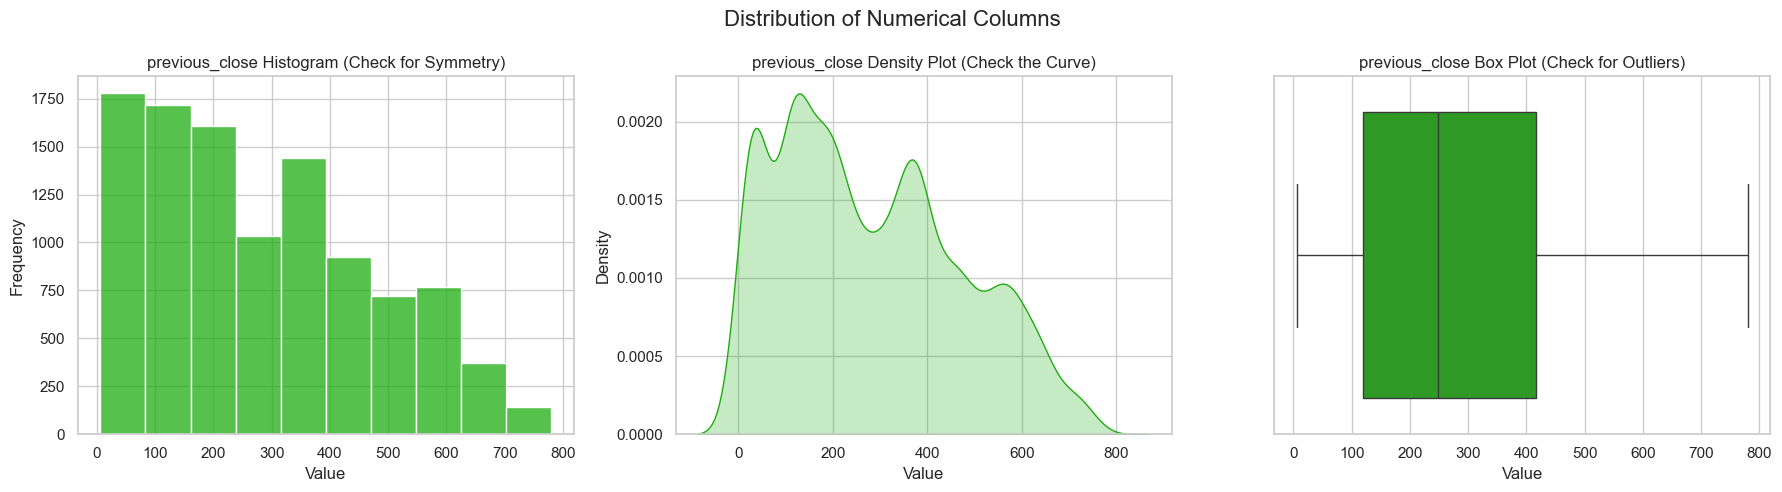

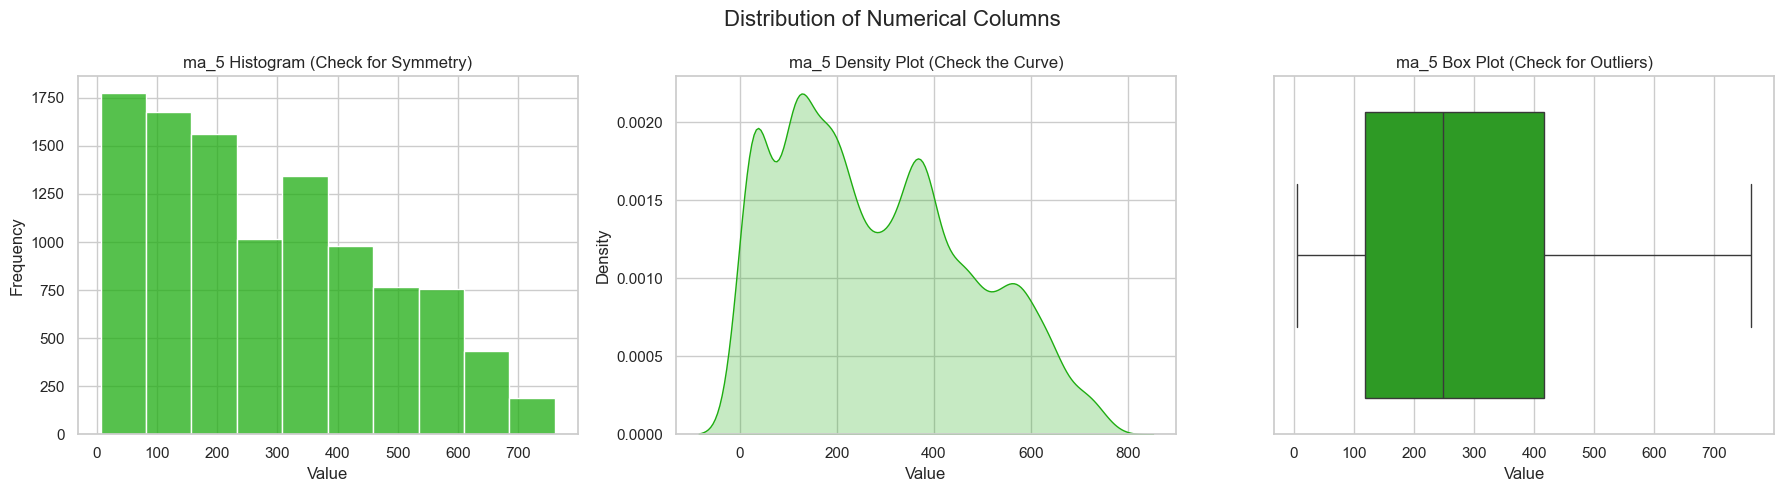

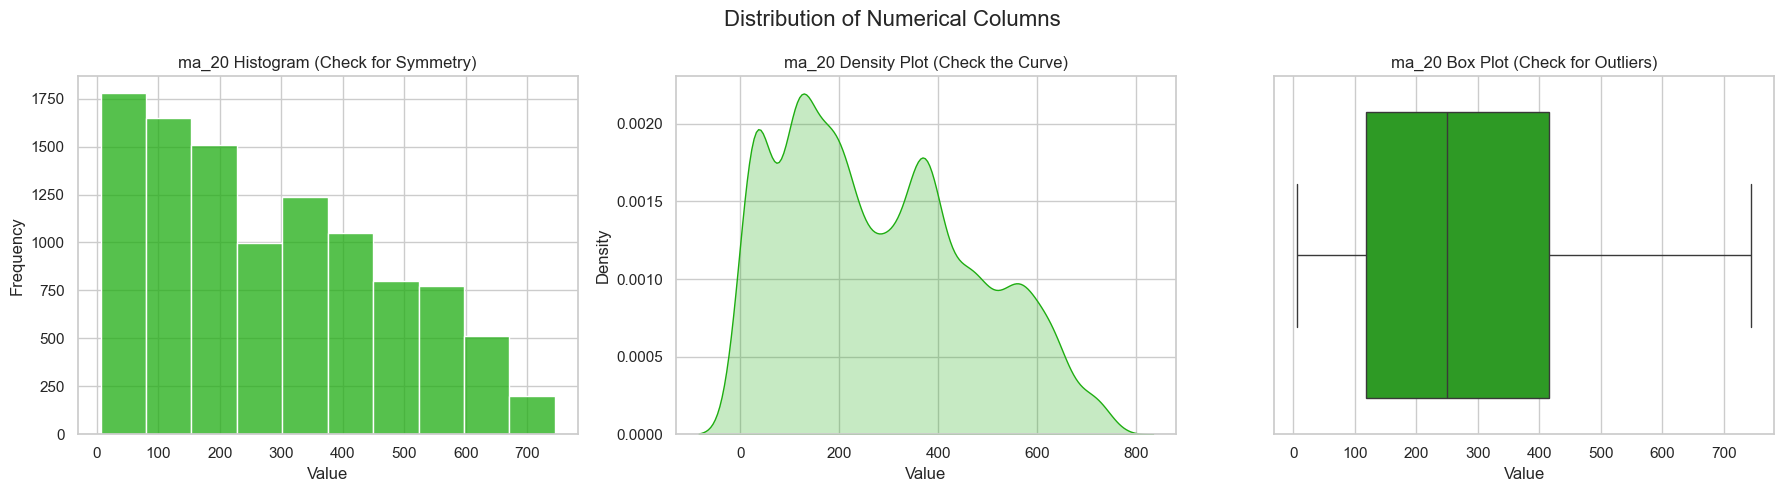

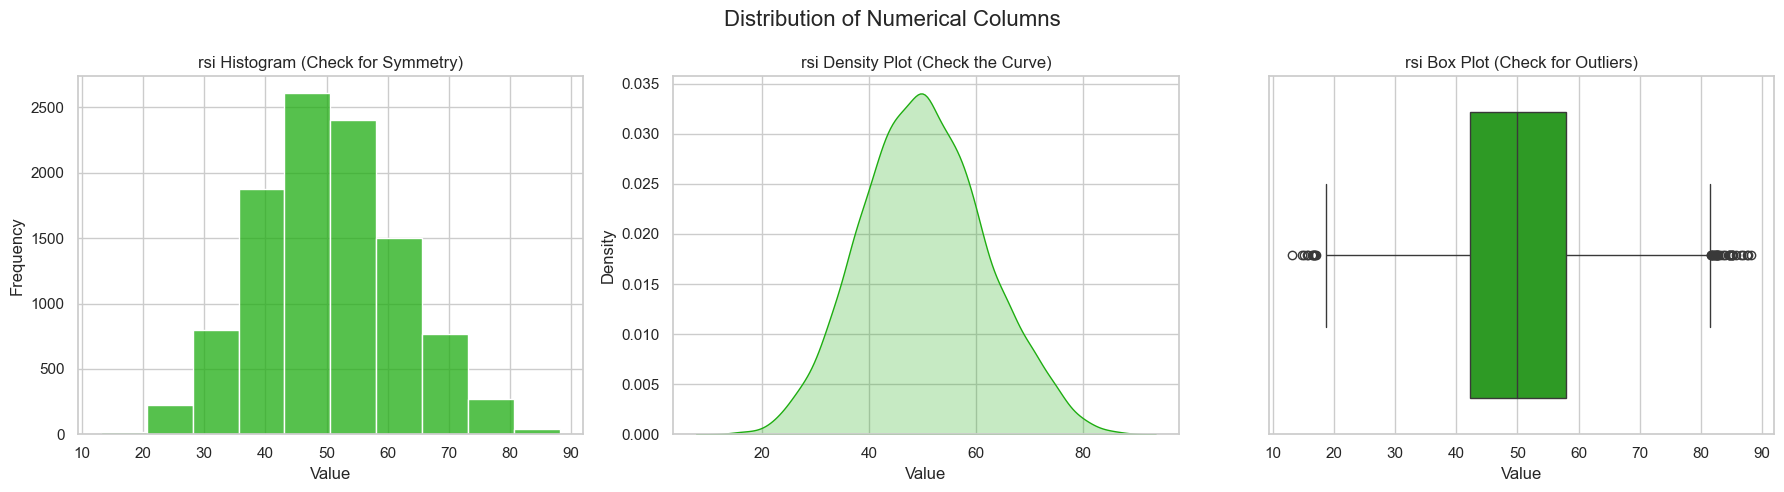

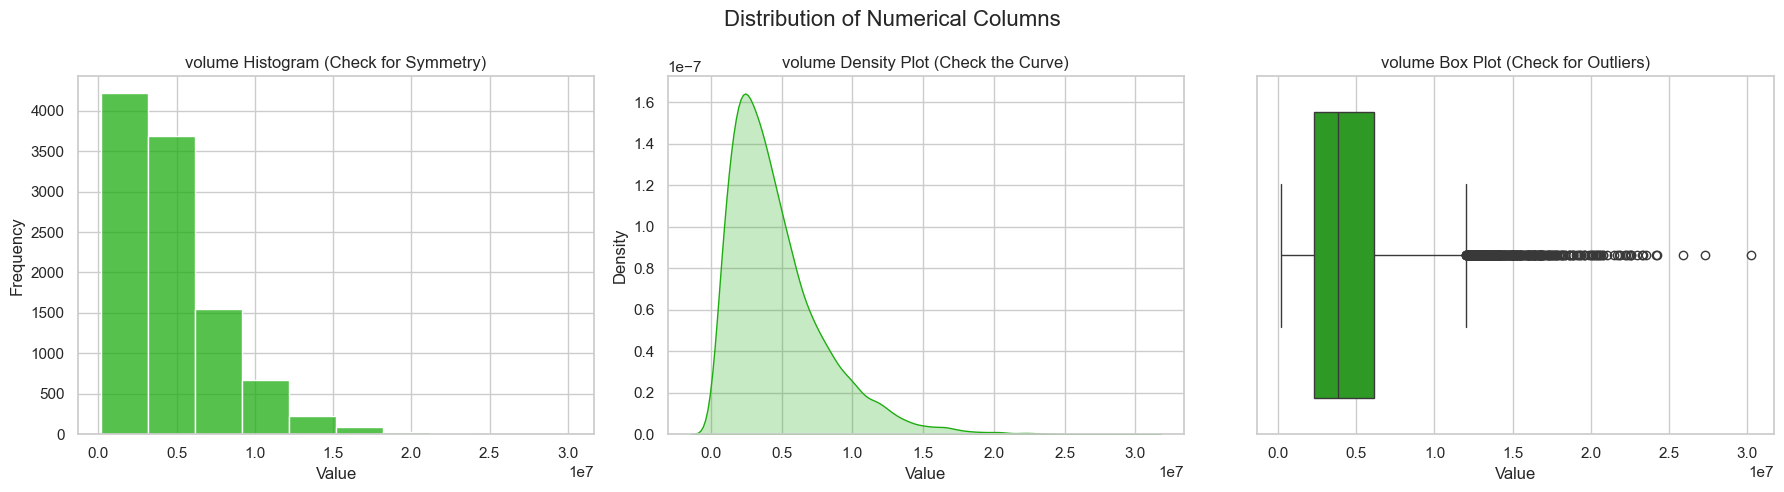

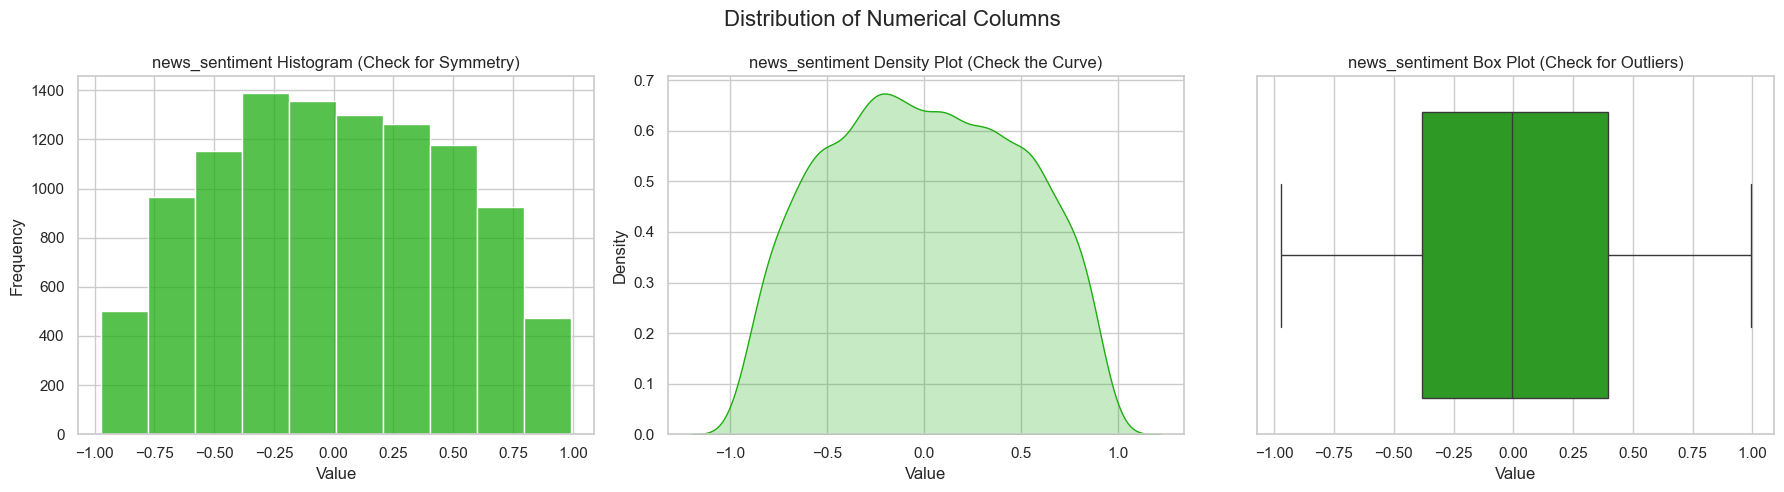

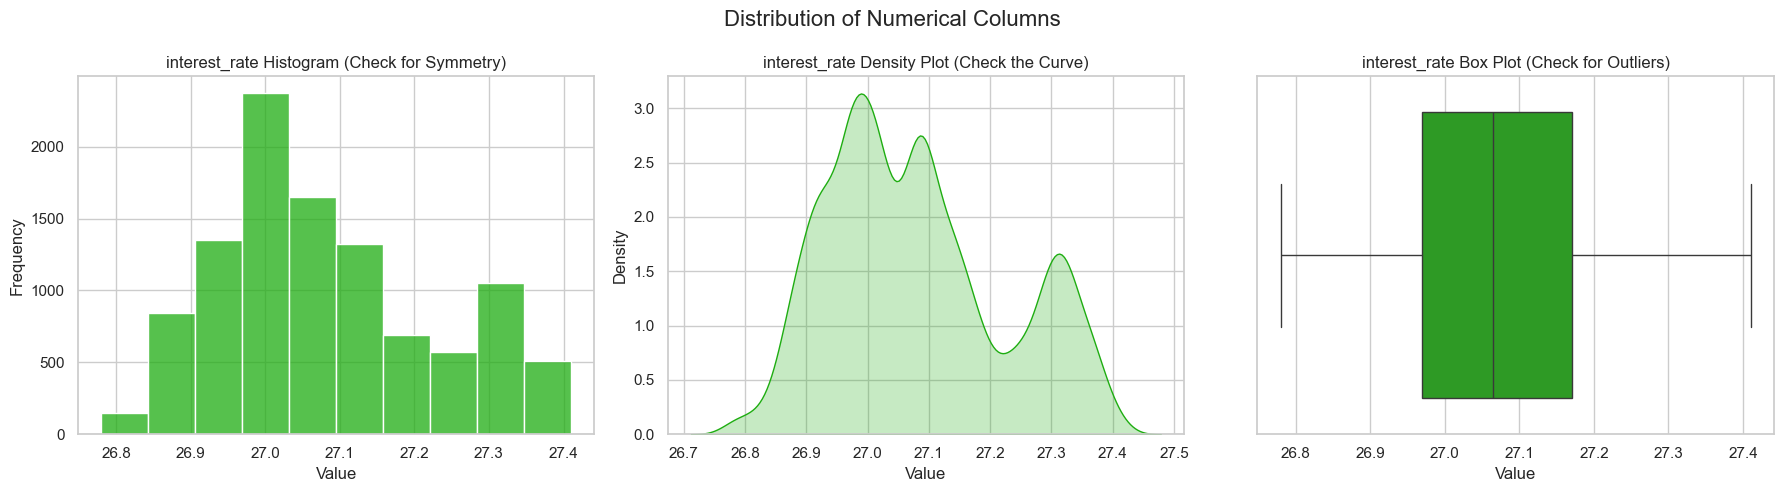

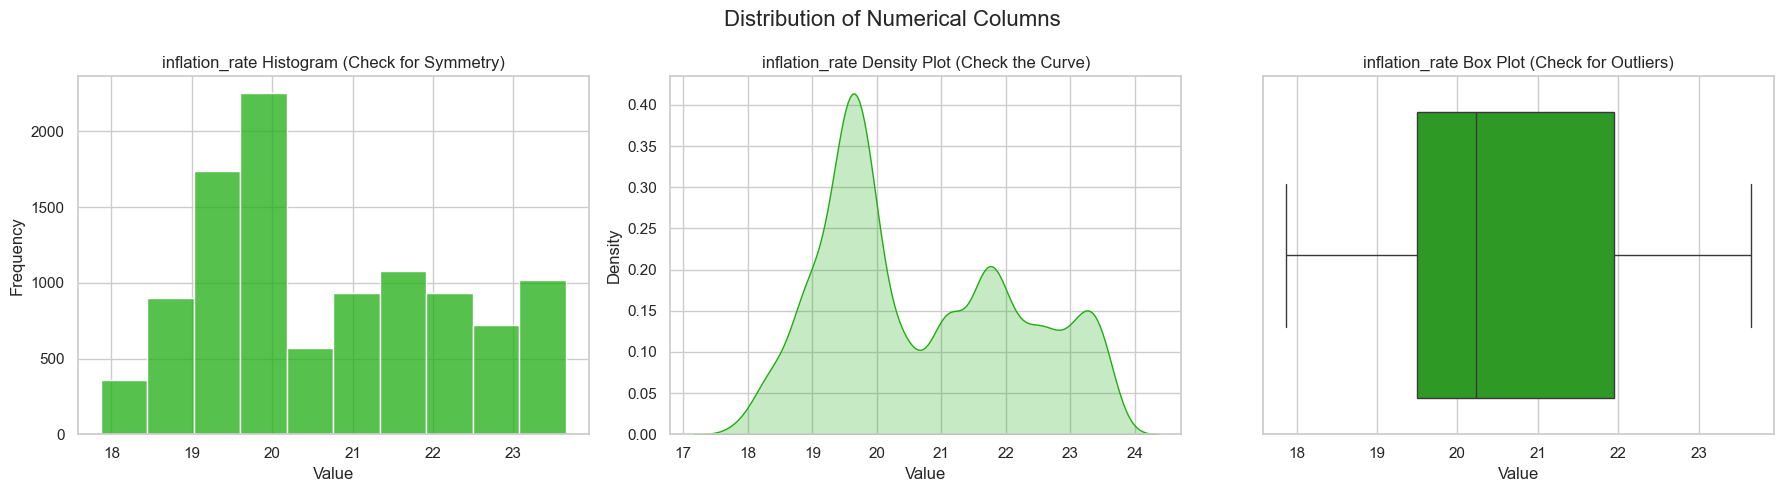

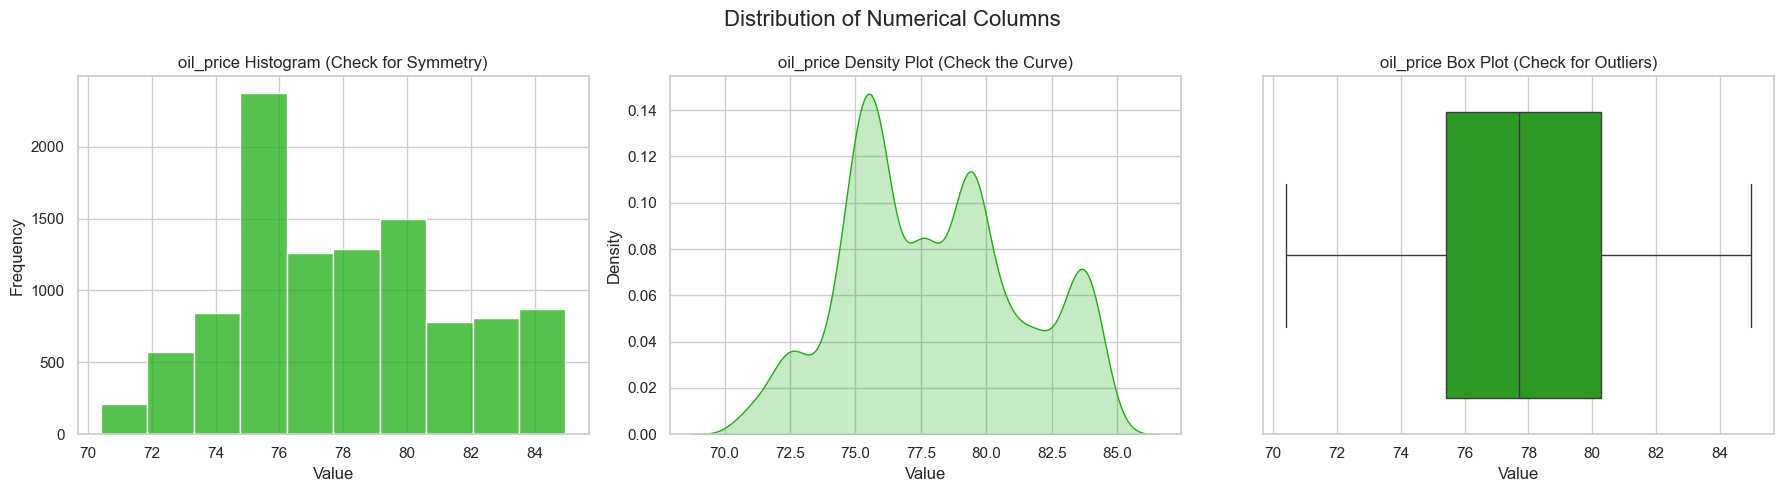

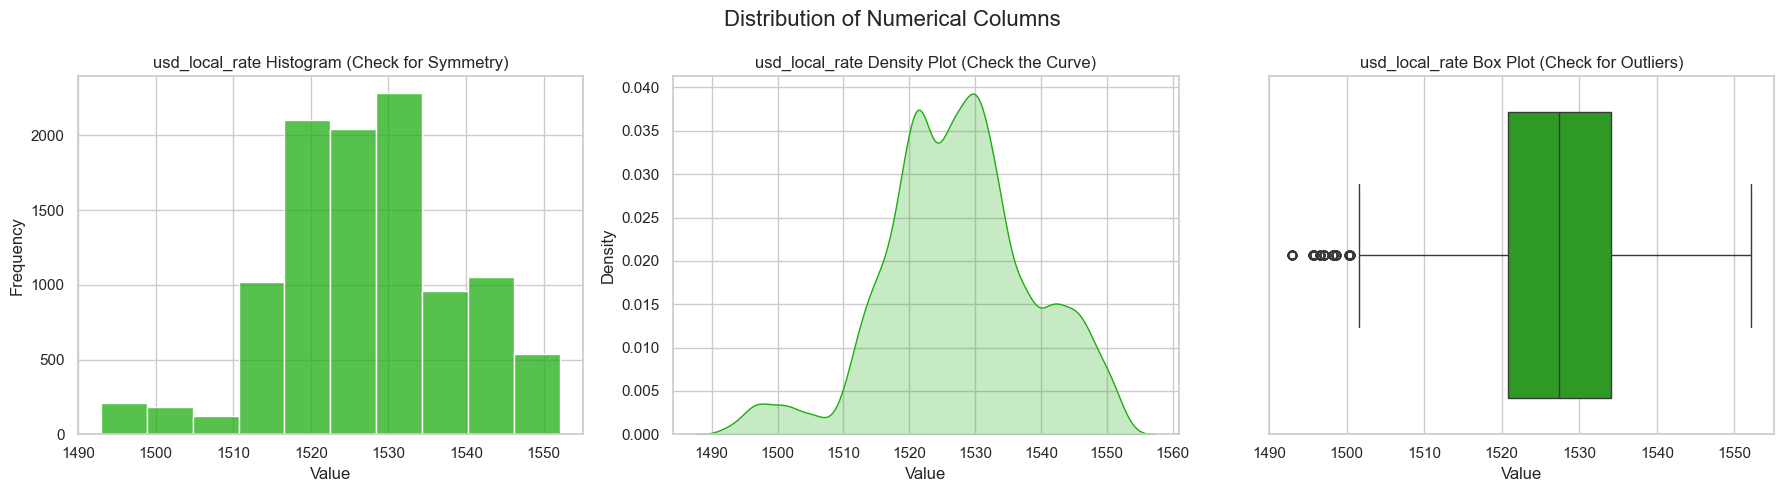

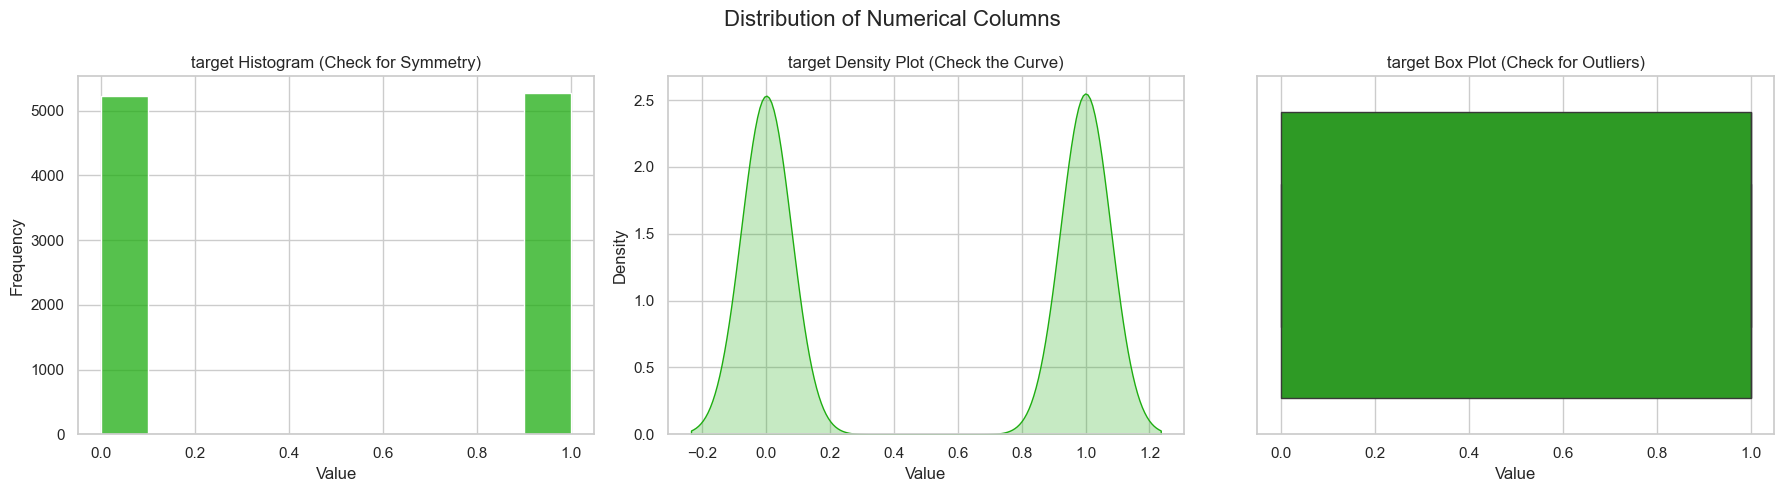

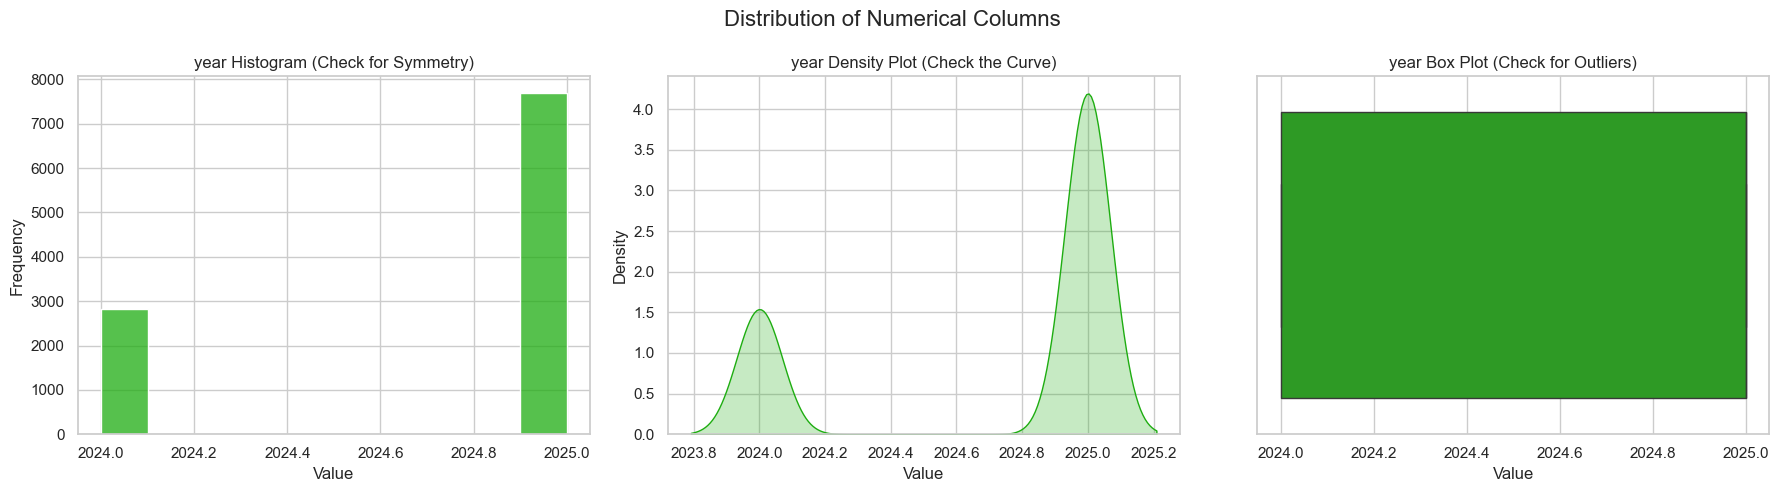

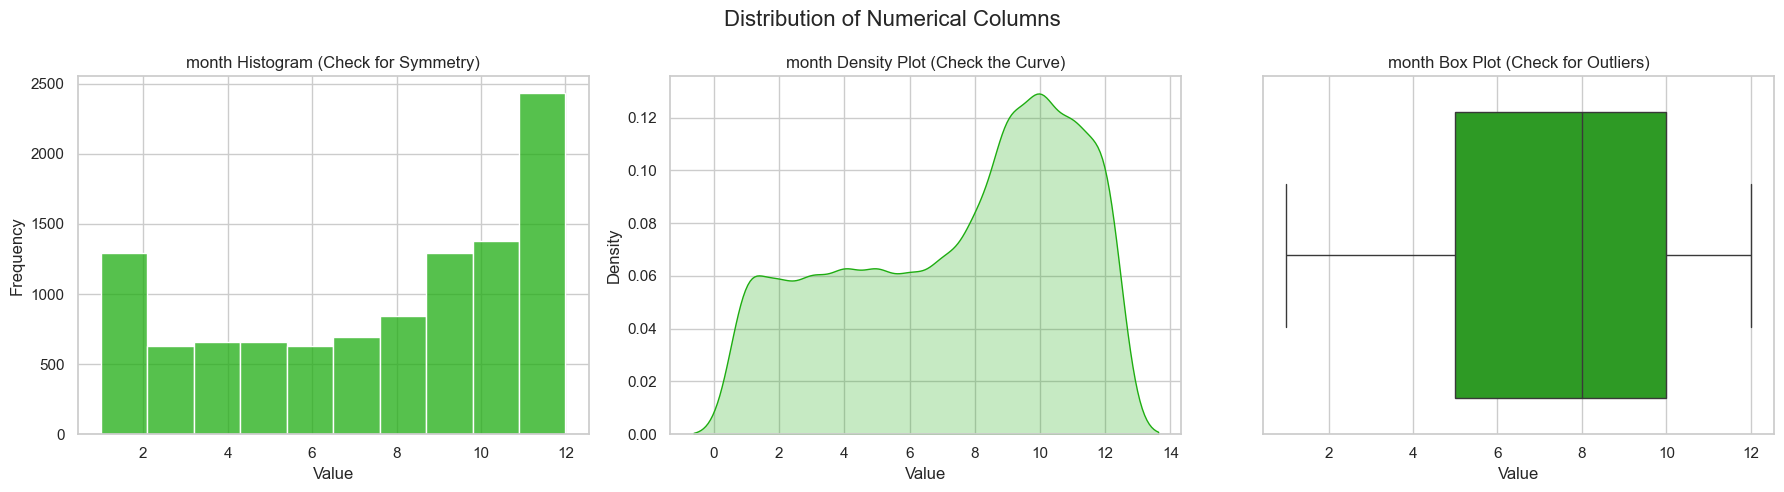

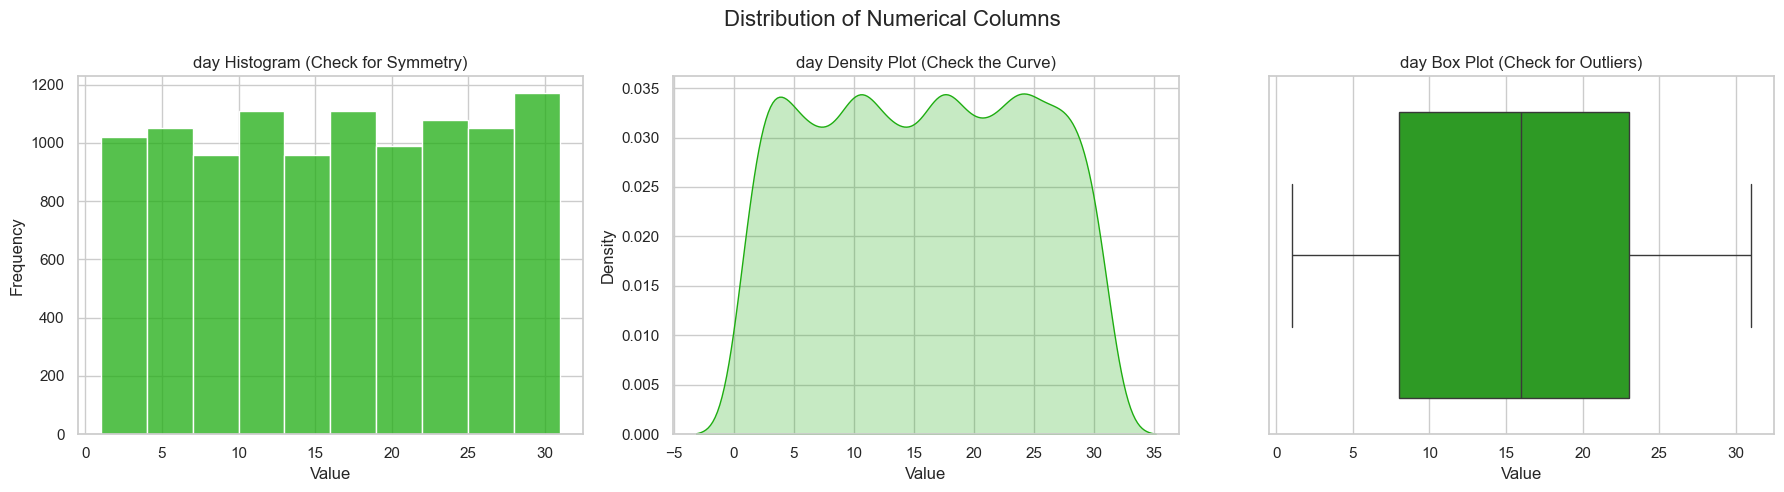

In [17]:
#visualization to show distribution of numerical features with train data type 
numeric_features = train_df.select_dtypes(include=['float','int']).columns 
# plots to check for outliers and understand distribution of train_data set 
sns.set_theme(style="whitegrid")
primary_color = "#1ead11"

for i in numeric_features:
    # create a figure with 3 subplots (1 row, 3 columns)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Distribution of Numerical Columns', fontsize=16)

    # histogram
    sns.histplot(train_df[i], bins=10, color=primary_color, ax=axes[0])
    axes[0].set_title(f'{i} Histogram (Check for Symmetry)')
    axes[0].set_xlabel('Value')
    axes[0].set_ylabel('Frequency')

    # density plot
    sns.kdeplot(train_df[i], color=primary_color, fill=True, ax=axes[1])
    axes[1].set_title(f'{i} Density Plot (Check the Curve)')
    axes[1].set_xlabel('Value')
    axes[1].set_ylabel('Density') 

    # boxplot
    sns.boxplot(x=train_df[i], color=primary_color, ax=axes[2])
    axes[2].set_title(f'{i} Box Plot (Check for Outliers)')
    axes[2].set_xlabel('Value')

    # display the charts
    plt.tight_layout()
    plt.show()  

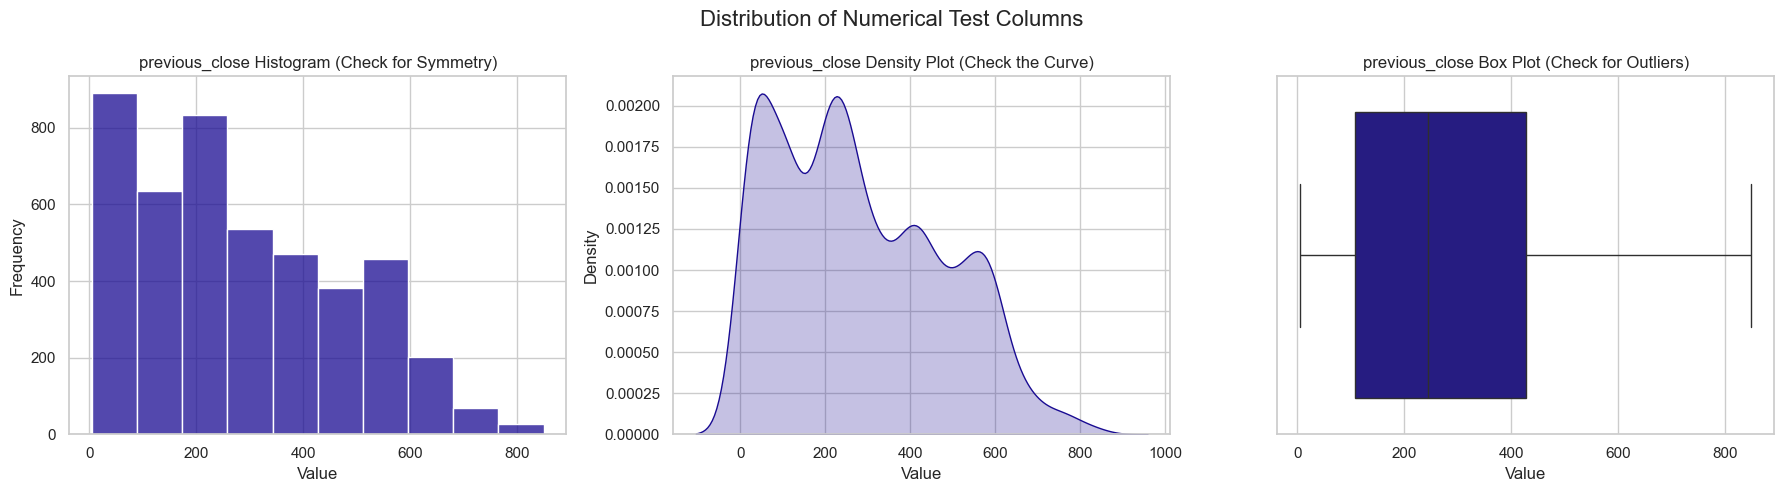

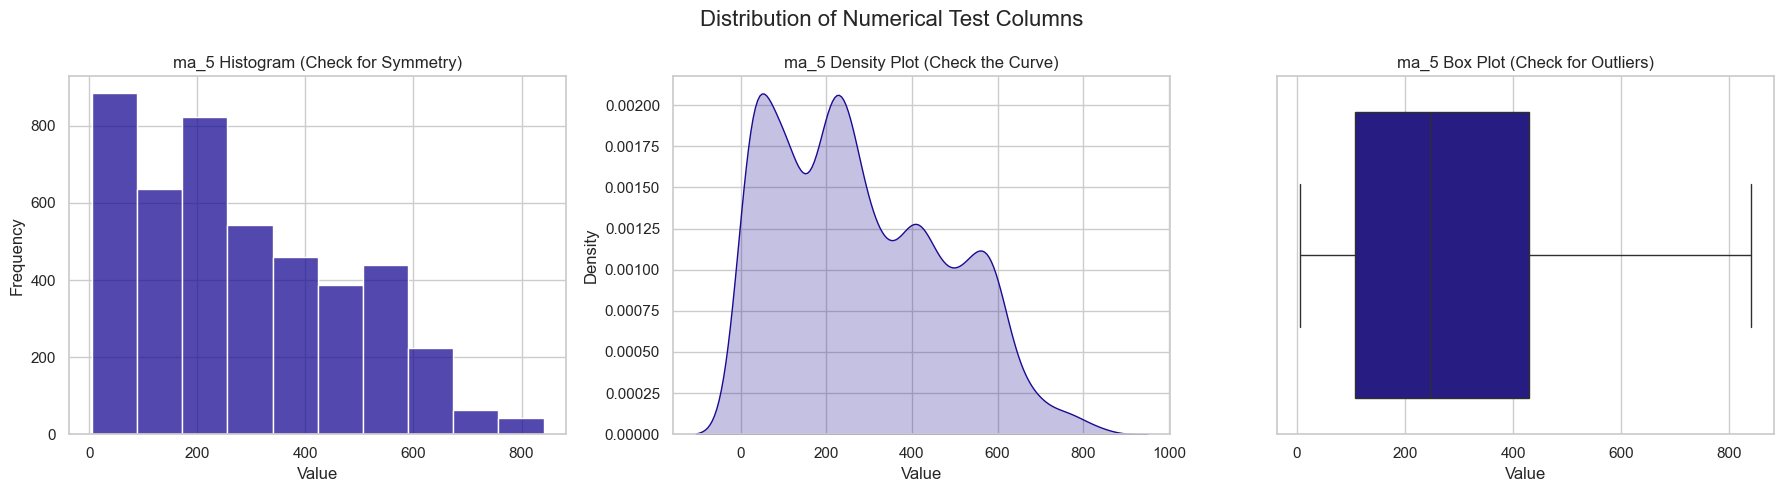

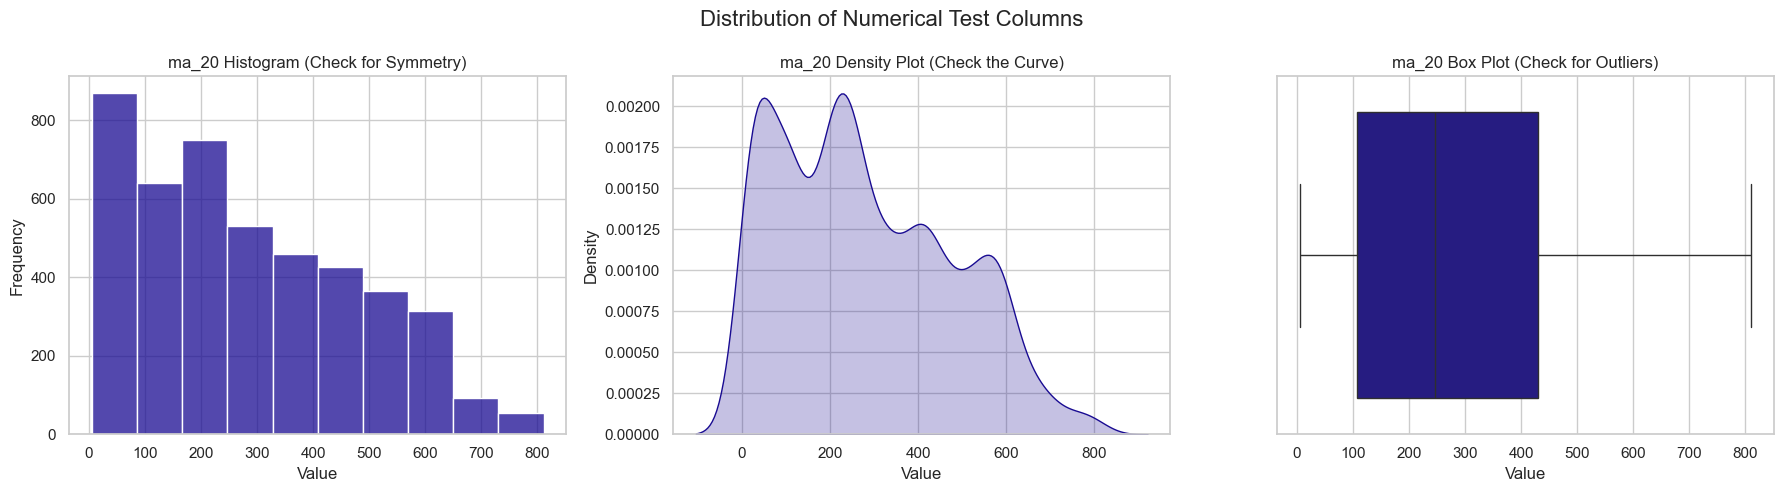

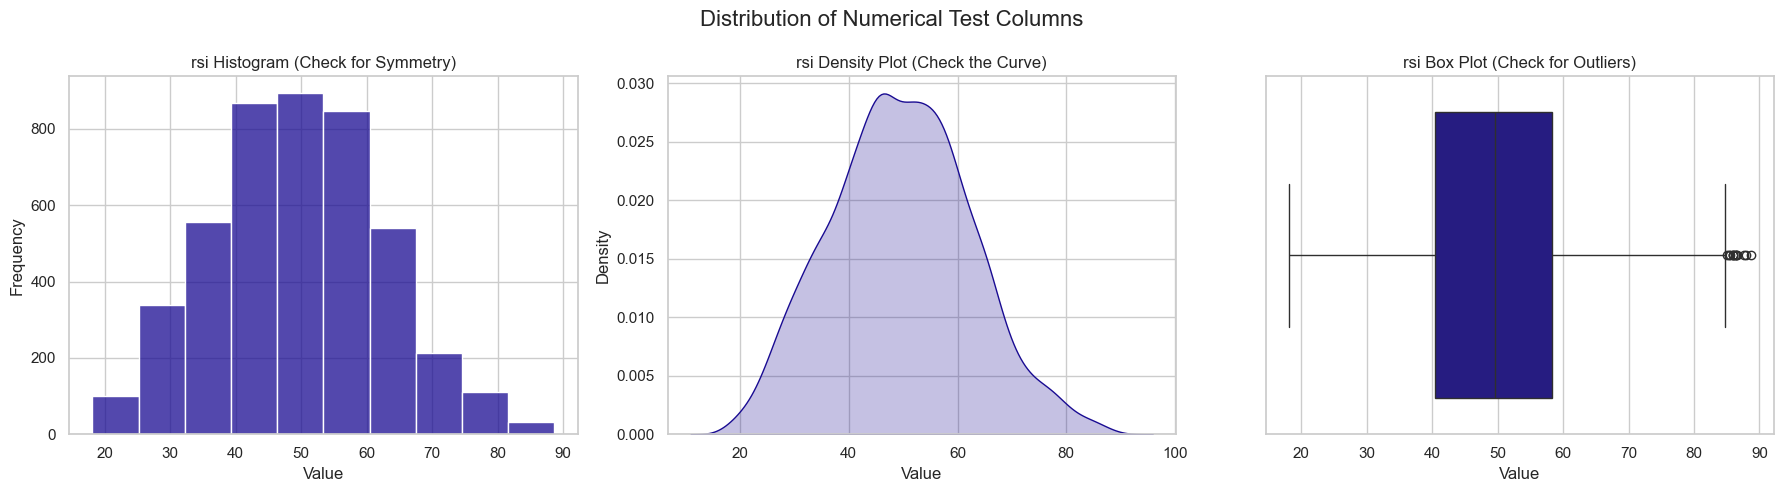

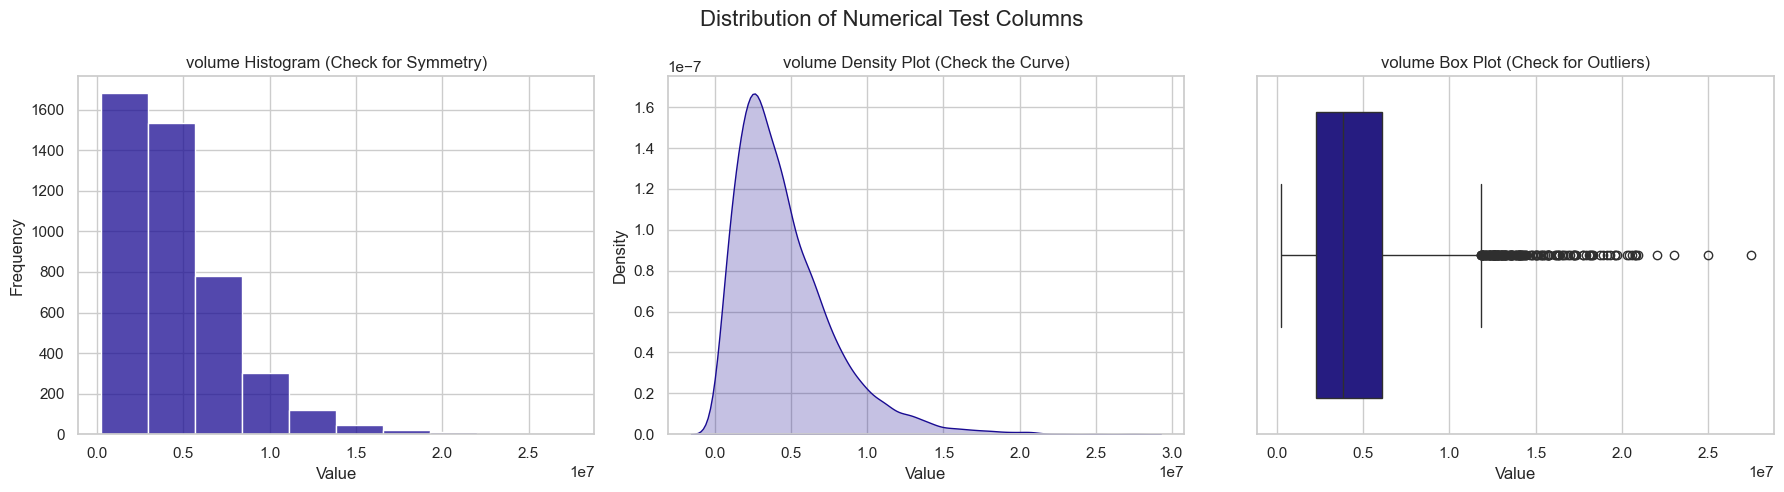

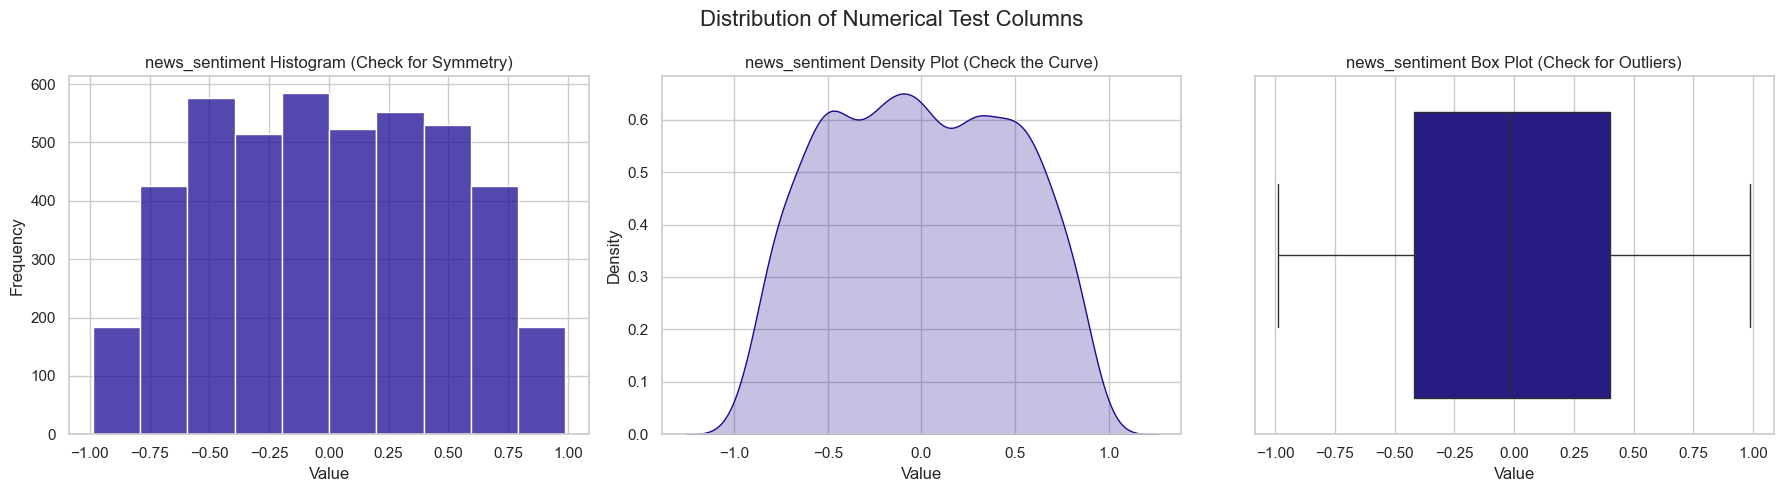

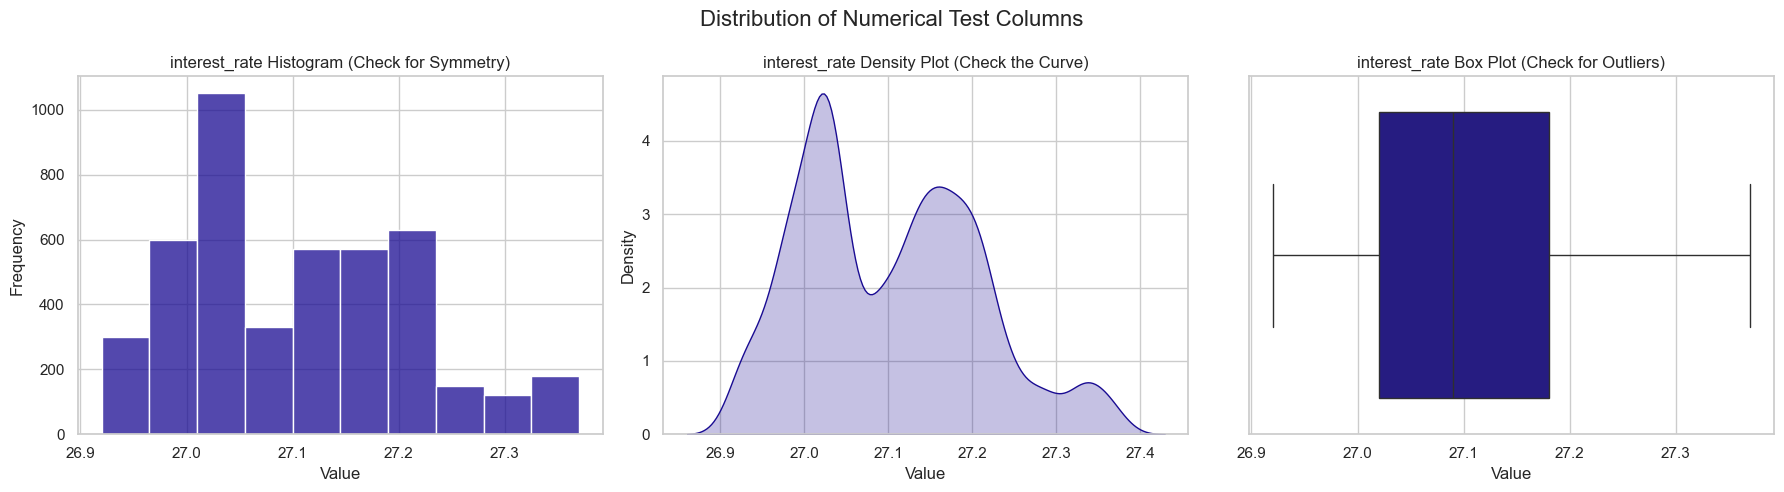

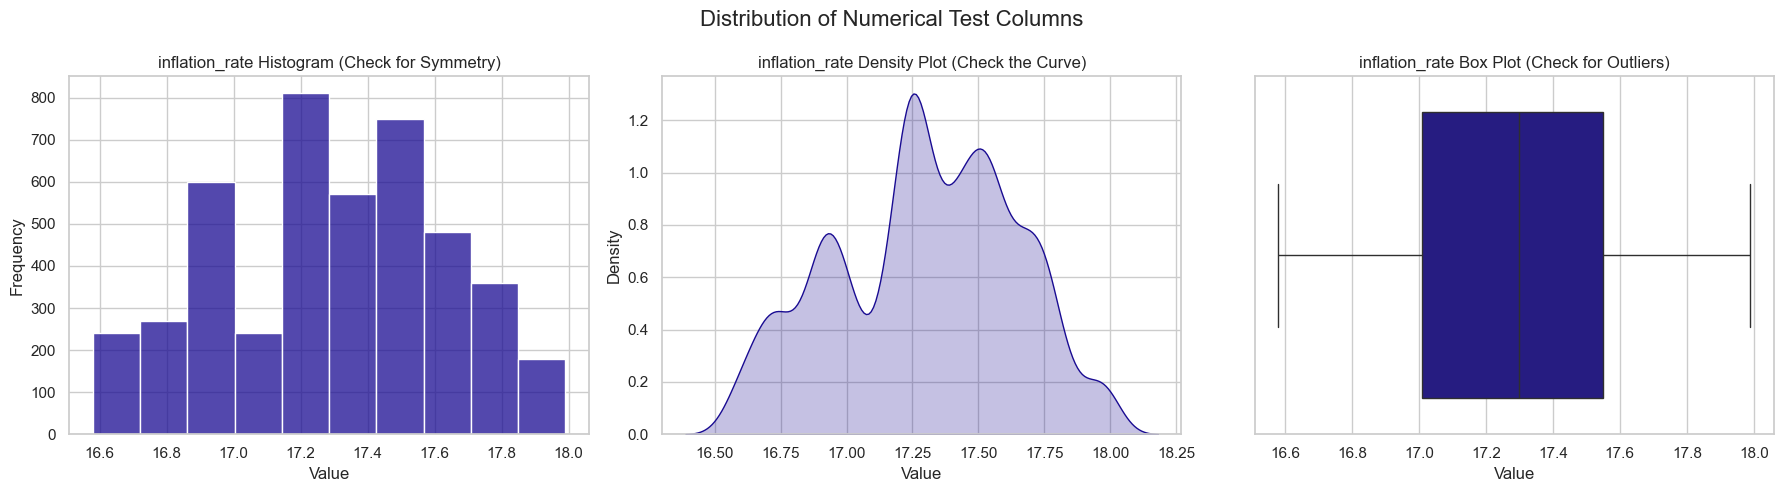

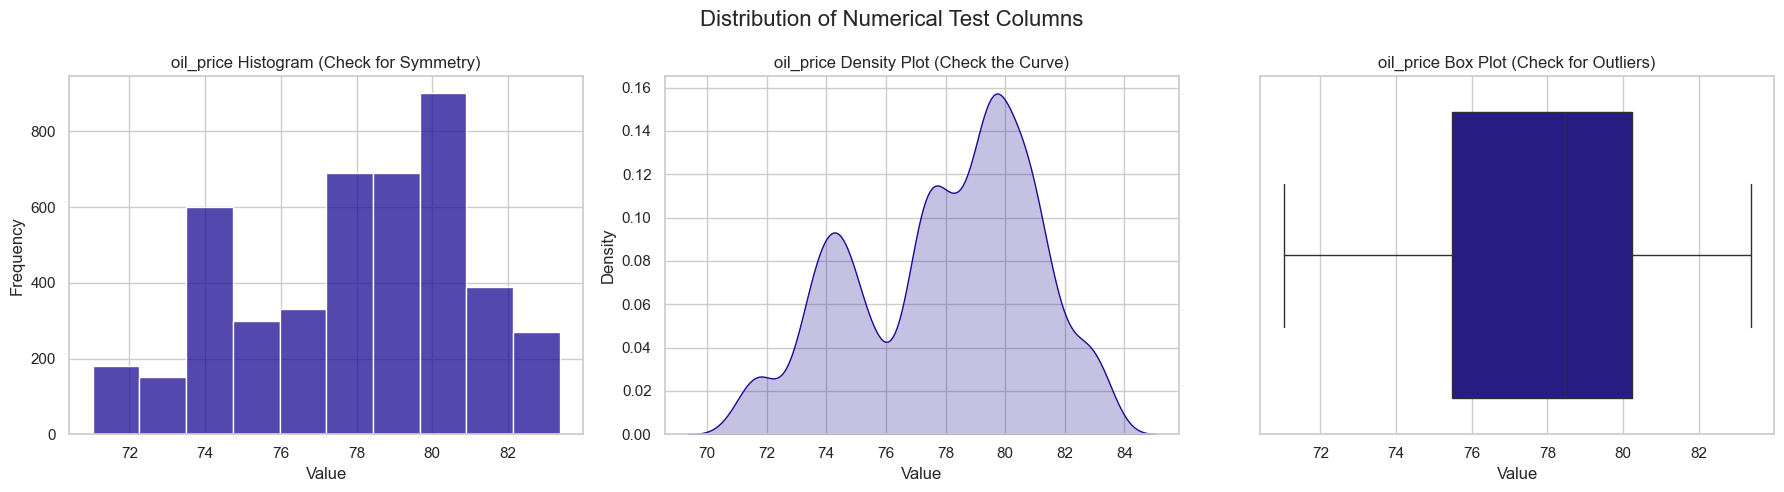

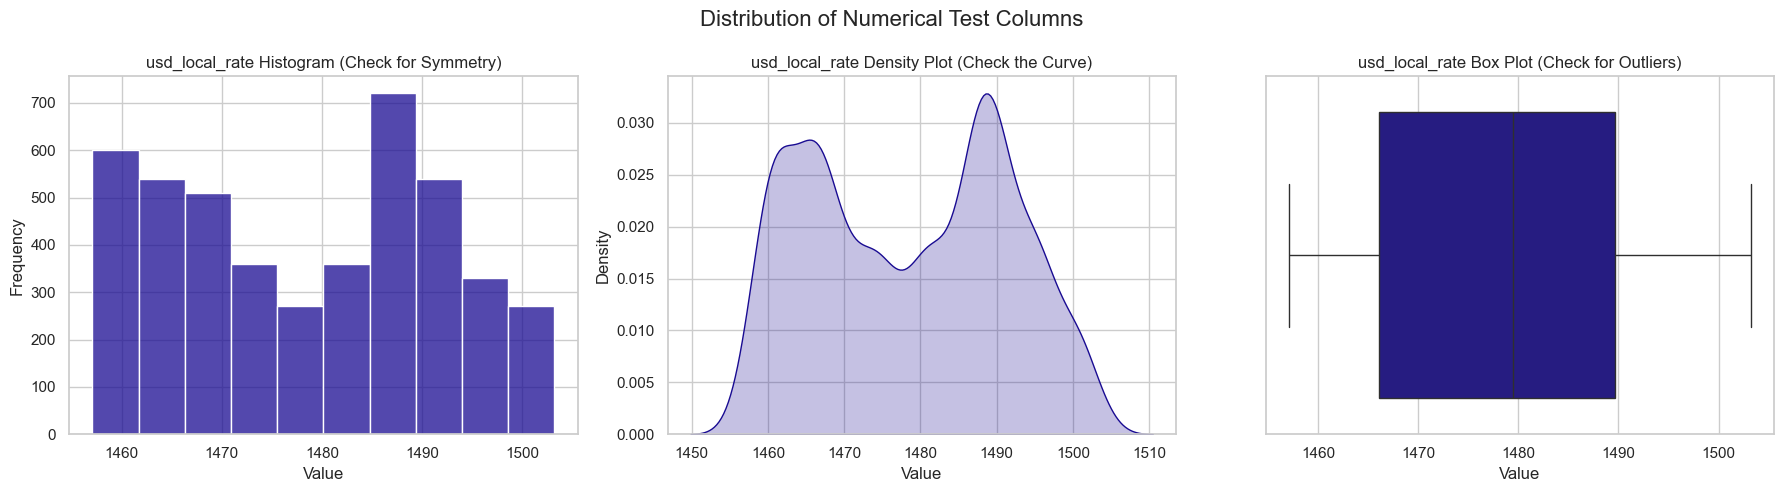

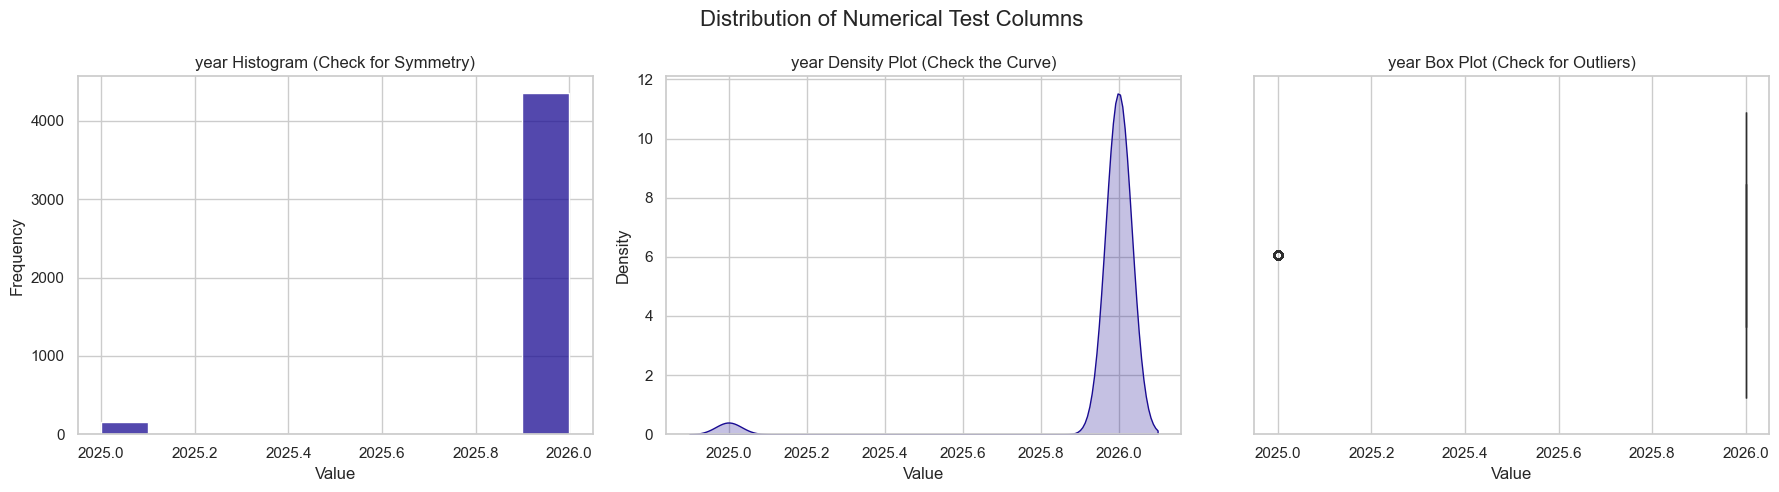

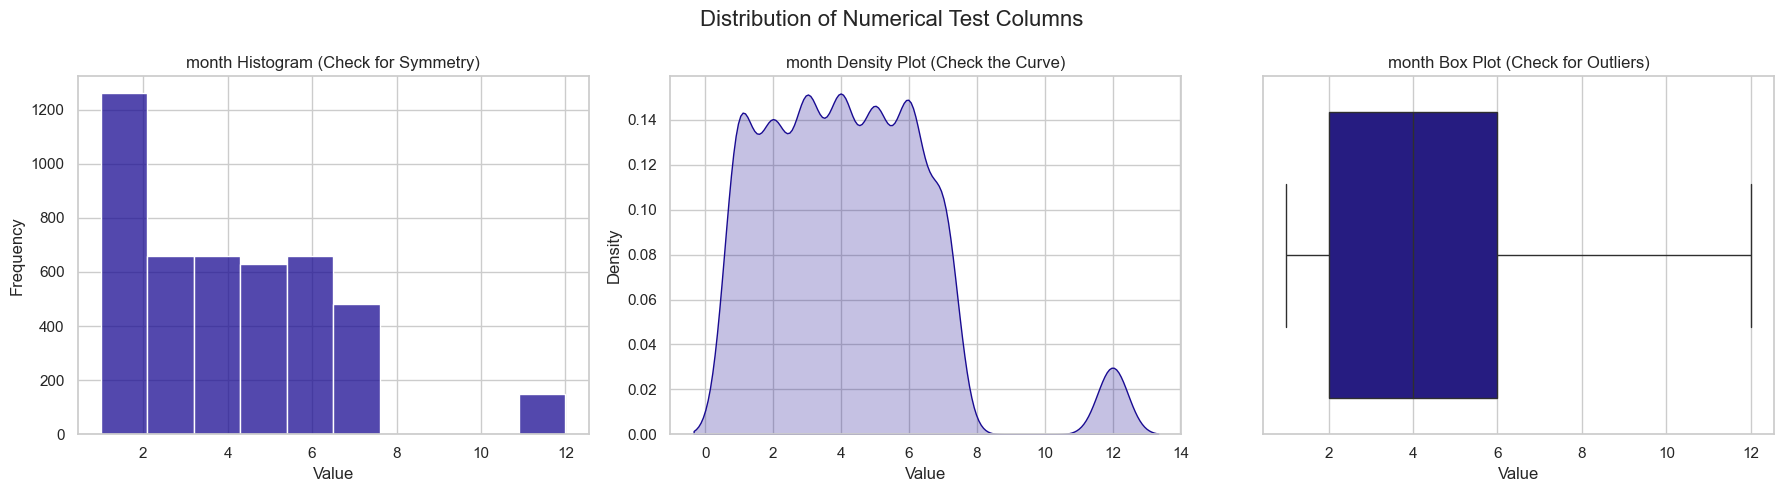

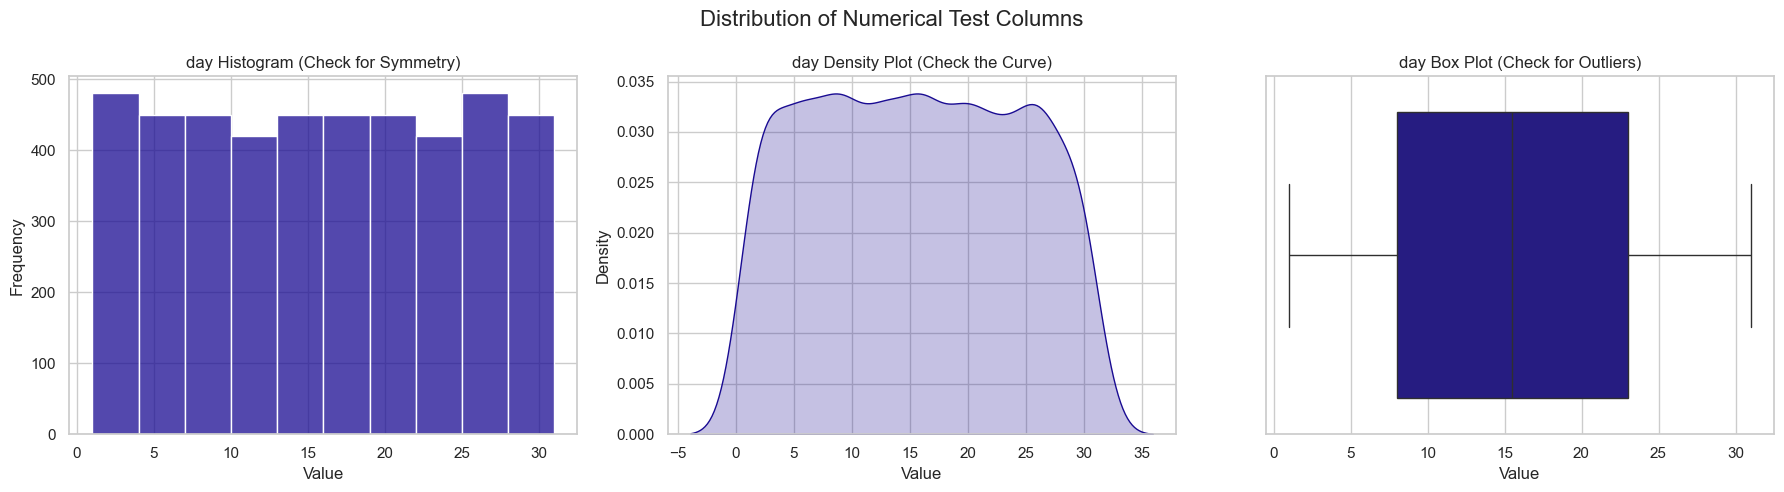

In [18]:
#visualization to show distribution of numerical features with test data 
numeric_features = test_df.select_dtypes(include=['float','int']).columns
# plots to check for outliers and understand distribution of test_data set 
sns.set_theme(style="whitegrid")
primary_color = "#190b92"

for i in numeric_features:
    # create a figure with 3 subplots (1 row, 3 columns)
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    fig.suptitle('Distribution of Numerical Test Columns', fontsize=16)

    # histogram
    sns.histplot(test_df[i], bins=10, color=primary_color, ax=axes[0])
    axes[0].set_title(f'{i} Histogram (Check for Symmetry)')
    axes[0].set_xlabel('Value')
    axes[0].set_ylabel('Frequency')

    # density plot
    sns.kdeplot(test_df[i], color=primary_color, fill=True, ax=axes[1])
    axes[1].set_title(f'{i} Density Plot (Check the Curve)')
    axes[1].set_xlabel('Value')
    axes[1].set_ylabel('Density') 

    # boxplot
    sns.boxplot(x=test_df[i], color=primary_color, ax=axes[2])
    axes[2].set_title(f'{i} Box Plot (Check for Outliers)')
    axes[2].set_xlabel('Value')

    # display the charts
    plt.tight_layout()
    plt.show()  

In [19]:

outlier_cols = [col for col in ['rsi', 'volume', 'usd_local_rate'] if col in train_df.columns] 

In [20]:
#categorizing numeric features on the train dataset
#numeric_features = train_df.select_dtypes(include=['float','int']).columns
# handling of outliers in train data set using IQR 
outlier_cols = ['rsi', 'volume', 'usd_local_rate']

for col in outlier_cols:

    Q1 = train_df[col].quantile(0.25)
    Q3 = train_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    train_df[col] = train_df[col].clip(lower=lower_bound, upper=upper_bound)     
 


In [21]:
#classification of outliers within test data set 
outlier_cols = ['volume']
#calculation of iqr 
for col in outlier_cols:

    Q1 = test_df[col].quantile(0.25)
    Q3 = test_df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    #clippping values into range
    test_df[col] = train_df[col].clip(lower=lower_bound, upper=upper_bound)     

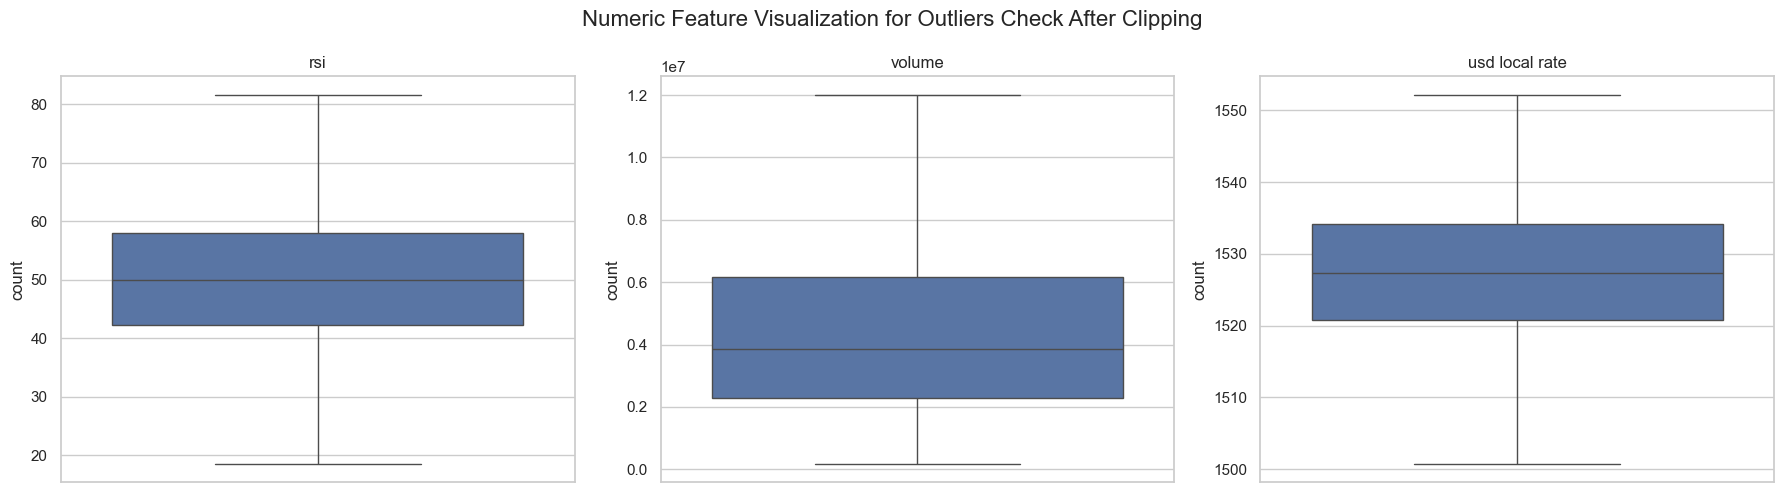

In [22]:
#box plot to check for outliers after clipping on train dataset 
numeric_features = ['rsi', 'volume', 'usd_local_rate']
fig, axes = plt.subplots(1, 3, figsize=(18,5 ))
fig.suptitle('Numeric Feature Visualization for Outliers Check After Clipping', fontsize=16)

for axis, feature in zip(axes.flatten(), numeric_features):
    sns.boxplot(data = train_df,  y = feature, ax = axis)
    axis.set_title(feature.replace('_', ' '))
    axis.set_ylabel('count') 

#axes.flatten()[-1].axis('off')
plt.tight_layout() 
plt.show() 

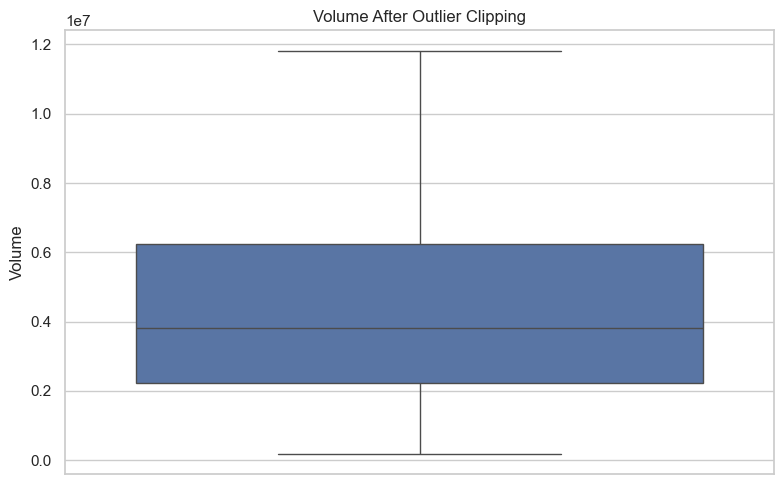

In [23]:

#plotting a box plot for outlier check on test data 

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=test_df, y='volume', ax=ax)

ax.set_title('Volume After Outlier Clipping')
ax.set_ylabel('Volume')

plt.tight_layout()
plt.show()

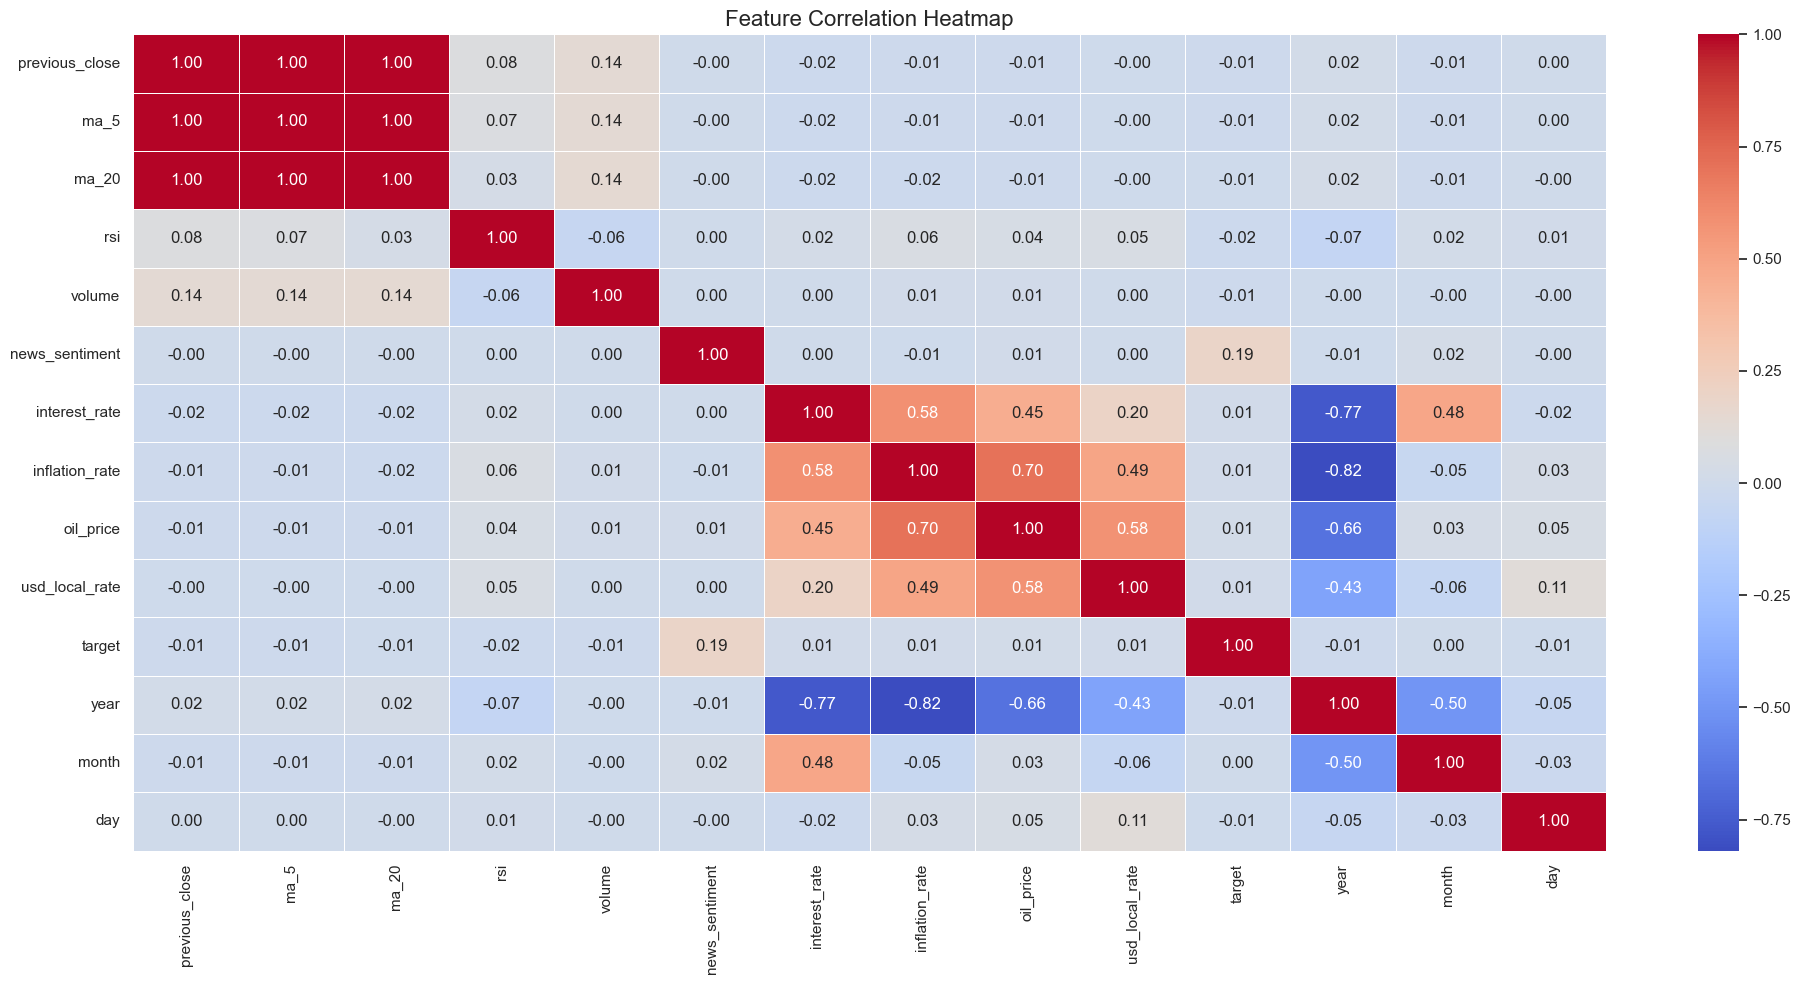

In [24]:

plt.figure(figsize=(20, 10))
# select only numerical columns for correlation
corr_df = train_df.select_dtypes(include=[np.number])
sns.heatmap(corr_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Feature Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show() 

In [25]:
from sklearn.pipeline import Pipeline 
# separate features and target
X = train_df.drop(columns=['target'])
y = train_df['target']


# split data before scaling and encoding
X_train, X_val, y_train, y_val = train_test_split (X, y, test_size=0.20, random_state=42, stratify=y)


# identify numerical and categorical columns
num_cols = X_train.select_dtypes(include=['number']).columns
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns


# numerical pipeline
num_pipeline = Pipeline ([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])


# categorical pipeline
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])


# combine preprocessing 
preprocessor = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('cat', cat_pipeline, cat_cols)
])


# fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)


# immediately convert processed data into DataFrames
feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

X_val_processed = pd.DataFrame(
    X_val_processed,
    columns=feature_names,
    index=X_val.index
)


print("Training data shape:", X_train_processed.shape)
print("Validation data shape:", X_val_processed.shape)

X_train_processed.head()

C:\Users\aggos\AppData\Local\Temp\ipykernel_4496\3915252641.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=['object', 'category']).columns


Training data shape: (8400, 44)
Validation data shape: (2100, 44)


,num__previous_close,num__ma_5,num__ma_20,num__rsi,num__volume,num__news_sentiment,num__interest_rate,num__inflation_rate,num__oil_price,num__usd_local_rate,...,cat__ticker_SEPLAT,cat__ticker_STANBIC,cat__ticker_STERLINGNG,cat__ticker_TRANSCORP,cat__ticker_UBA,cat__ticker_UNILEVER,cat__ticker_WAPCO,cat__ticker_WEMABANK,cat__ticker_ZENITHBANK,cat__country_Nigeria
2595,0.800468,0.779892,0.726756,0.521048,-0.589661,-1.040722,-0.007082,0.784820,1.200547,2.098444,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
6210,0.931308,0.862331,0.906266,0.135645,-1.030004,-0.698906,0.268009,-0.767541,-0.181708,0.179449,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4223,0.520134,0.473889,0.388880,1.475048,0.144703,1.209048,-1.038675,0.269568,0.484368,-0.219622,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2794,-0.090732,-0.091337,-0.169584,1.751570,-0.913730,-1.651847,-0.557265,0.725368,1.645580,1.875728,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1176,0.744768,0.719373,0.635607,1.901065,-0.389035,0.753294,1.987330,1.564304,1.262439,0.442163,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [26]:
RANDOM_STATE = 42 
baseline_rf = RandomForestClassifier (n_estimators=100, random_state=RANDOM_STATE)
 
baseline_rf.fit(X_train_processed, y_train)



# Predict on validation set
val_preds = baseline_rf.predict(X_val_processed)
val_probs = baseline_rf.predict_proba(X_val_processed)[:, 1]  # needed for ROC-AUC

# metrics
accuracy  = accuracy_score(y_val, val_preds)
precision = precision_score(y_val, val_preds)
recall    = recall_score(y_val, val_preds)
f1        = f1_score(y_val, val_preds)
roc_auc   = roc_auc_score(y_val, val_probs)

print("=== Baseline Random Forest — Validation Metrics ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification Report:\n", classification_report(y_val, val_preds))
print("Confusion Matrix:\n", confusion_matrix(y_val, val_preds)) 

=== Baseline Random Forest — Validation Metrics ===
Accuracy:  0.5424
Precision: 0.5449
Recall:    0.5299
F1 Score:  0.5373
ROC-AUC:   0.5753

Classification Report:
               precision    recall  f1-score   support

           0       0.54      0.55      0.55      1047
           1       0.54      0.53      0.54      1053

    accuracy                           0.54      2100
   macro avg       0.54      0.54      0.54      2100
weighted avg       0.54      0.54      0.54      2100

Confusion Matrix:
 [[581 466]
 [495 558]]


In [27]:
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
rfc_param_dist = {'n_estimators': [200,300,500,800], 'max_depth': [5,10,15,20,None],
    'min_samples_split': [2,5,10],
    'min_samples_leaf': [1,2,4],
    'max_features': ['sqrt','log2',None],
    'bootstrap': [True,False],
    'class_weight': ['balanced',None] } 

rfc_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=RANDOM_STATE),
    param_distributions=rfc_param_dist,
    n_iter=10,
    scoring='recall',
    cv=cv_strategy,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbose=0
)

rfc_search.fit(X_train_processed, y_train)

best_rfc = rfc_search.best_estimator_

print("Best Parameters:")
print(rfc_search.best_params_)

val_preds = best_rfc.predict(X_val_processed)
val_probs = best_rfc.predict_proba(X_val_processed)[:, 1]

accuracy = accuracy_score(y_val, val_preds)
precision = precision_score(y_val, val_preds)
recall = recall_score(y_val, val_preds)
f1 = f1_score(y_val, val_preds)
roc_auc = roc_auc_score(y_val, val_probs)

print("\n=== Tuned Random Forest Validation Metrics ===")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")


Best Parameters:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': None, 'max_depth': 15, 'class_weight': None, 'bootstrap': True}

=== Tuned Random Forest Validation Metrics ===
Accuracy:  0.5671
Precision: 0.5673
Recall:    0.5764
F1 Score:  0.5718
ROC-AUC:   0.6039


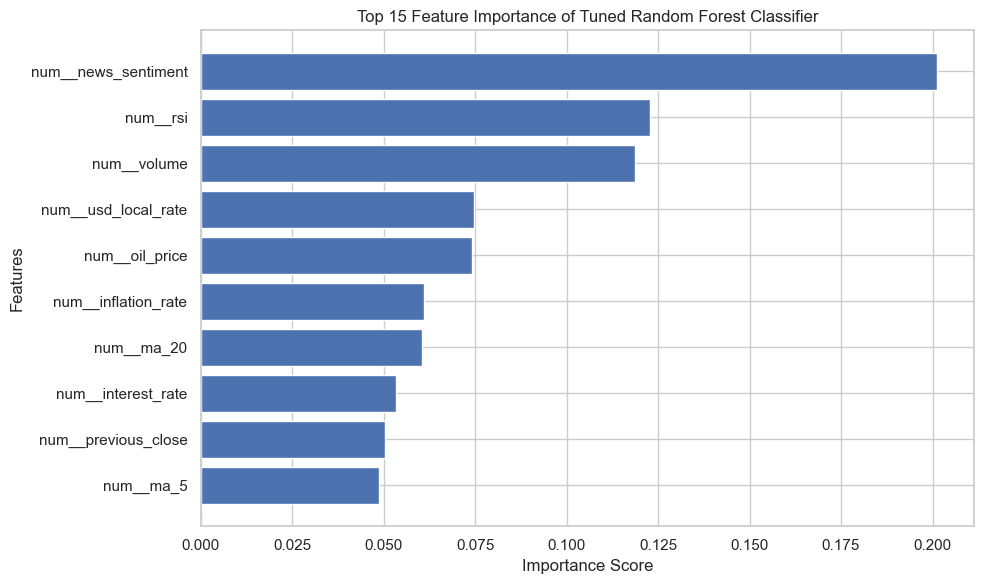

In [33]:
# extract the tuned Random Forest model
best_rf = rfc_search.best_estimator_ 

# create a dataframe containing the feature names and their importance scores
feature_importance = pd.DataFrame({ "Feature": X_train_processed.columns, "Importance": best_rf.feature_importances_ })

# select the top 10 features
top_features = feature_importance.head(10).sort_values( by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.gca().invert_yaxis()

plt.title("Top 15 Feature Importance of Tuned Random Forest Classifier")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [28]:
def stockmarket_finance_features(df):

    df = df.copy()

    # Adaptive Market Hypothesis
    df["Trend_Strength"] = (df["ma_5"] - df["ma_20"]) / df["ma_20"]
    df["Momentum"] = (df["previous_close"] - df["ma_5"]) / df["ma_5"]
    df["Trend_Direction"] = (df["ma_5"] > df["ma_20"]).astype(int)
    df["Relative_RSI"] = df["rsi"] - 50

    # Arbitrage Pricing Theory
    df["Real_Interest_Rate"] = df["interest_rate"] - df["inflation_rate"]
    df["Oil_FX_Ratio"] = df["oil_price"] / df["usd_local_rate"]
    df["Economic_Stress"] = (df["interest_rate"] + df["inflation_rate"] + df["usd_local_rate"])
    df["Import_Cost"] = ( df["usd_local_rate"] * df["interest_rate"])

    # Behavioural Finance
    df["Sentiment_Impact"] = ( df["news_sentiment"] * df["volume"])
    df["Buying_Pressure"] = ( df["news_sentiment"] * df["rsi"])
    df["Speculation_Index"] = ( df["volume"] * (1 - abs(df["news_sentiment"])))

    # Valuation Proxies
    df["Price_Premium"] = ( df["previous_close"] / df["ma_20"])
    df["Mean_Reversion"] = ( df["previous_close"] -  df["ma_20"])

    return df

#apply  finance based feature engineering to both data's 
train_finance_eng= stockmarket_finance_features(train_df)
test_finance_eng = stockmarket_finance_features (test_df)  

In [29]:
def market_features(df):

    df = df.copy()

    # Liquidity
    df["Relative_Volume"] = ( df["volume"] / df.groupby("ticker")["volume"].transform("mean"))
    df["Liquidity_Score"] = ( df["volume"] * df["previous_close"])

    # Volatility
    df["MA_Spread"] = (df["ma_5"] - df["ma_20"])
    df["Relative_Spread"] = ((df["ma_5"] - df["ma_20"]) / df["previous_close"])
    df["RSI_Strength"] = abs(df["rsi"] - 50)

    # NGX-specific
    df["Oil_Revenue_Index"] = ( df["oil_price"] *  df["usd_local_rate"])
    df["Naira_Strength"] = (1 / df["usd_local_rate"])
    df["Oil_Inflation"] = (df["oil_price"] / df["inflation_rate"])

    return df

train_markfea = market_features(train_finance_eng)
test_markfea =  market_features (test_finance_eng) 


In [30]:
train_markfea.columns 

Index(['ticker', 'country', 'previous_close', 'ma_5', 'ma_20', 'rsi', 'volume',
       'news_sentiment', 'interest_rate', 'inflation_rate', 'oil_price',
       'usd_local_rate', 'target', 'year', 'month', 'day', 'Trend_Strength',
       'Momentum', 'Trend_Direction', 'Relative_RSI', 'Real_Interest_Rate',
       'Oil_FX_Ratio', 'Economic_Stress', 'Import_Cost', 'Sentiment_Impact',
       'Buying_Pressure', 'Speculation_Index', 'Price_Premium',
       'Mean_Reversion', 'Relative_Volume', 'Liquidity_Score', 'MA_Spread',
       'Relative_Spread', 'RSI_Strength', 'Oil_Revenue_Index',
       'Naira_Strength', 'Oil_Inflation'],
      dtype='str')

In [31]:
train_markfea.isnull().sum() 

ticker                0
country               0
previous_close        0
ma_5                  0
ma_20                 0
rsi                   0
volume                0
news_sentiment        0
interest_rate         0
inflation_rate        0
oil_price             0
usd_local_rate        0
target                0
year                  0
month                 0
day                   0
Trend_Strength        0
Momentum              0
Trend_Direction       0
Relative_RSI          0
Real_Interest_Rate    0
Oil_FX_Ratio          0
Economic_Stress       0
Import_Cost           0
Sentiment_Impact      0
Buying_Pressure       0
Speculation_Index     0
Price_Premium         0
Mean_Reversion        0
Relative_Volume       0
Liquidity_Score       0
MA_Spread             0
Relative_Spread       0
RSI_Strength          0
Oil_Revenue_Index     0
Naira_Strength        0
Oil_Inflation         0
dtype: int64

In [32]:
test_markfea.isnull().sum()

ticker                0
country               0
previous_close        0
ma_5                  0
ma_20                 0
rsi                   0
volume                0
news_sentiment        0
interest_rate         0
inflation_rate        0
oil_price             0
usd_local_rate        0
year                  0
month                 0
day                   0
Trend_Strength        0
Momentum              0
Trend_Direction       0
Relative_RSI          0
Real_Interest_Rate    0
Oil_FX_Ratio          0
Economic_Stress       0
Import_Cost           0
Sentiment_Impact      0
Buying_Pressure       0
Speculation_Index     0
Price_Premium         0
Mean_Reversion        0
Relative_Volume       0
Liquidity_Score       0
MA_Spread             0
Relative_Spread       0
RSI_Strength          0
Oil_Revenue_Index     0
Naira_Strength        0
Oil_Inflation         0
dtype: int64

In [53]:
print(train_markfea["target"].value_counts(normalize=True) * 100)

target
1    50.161905
0    49.838095
Name: proportion, dtype: float64


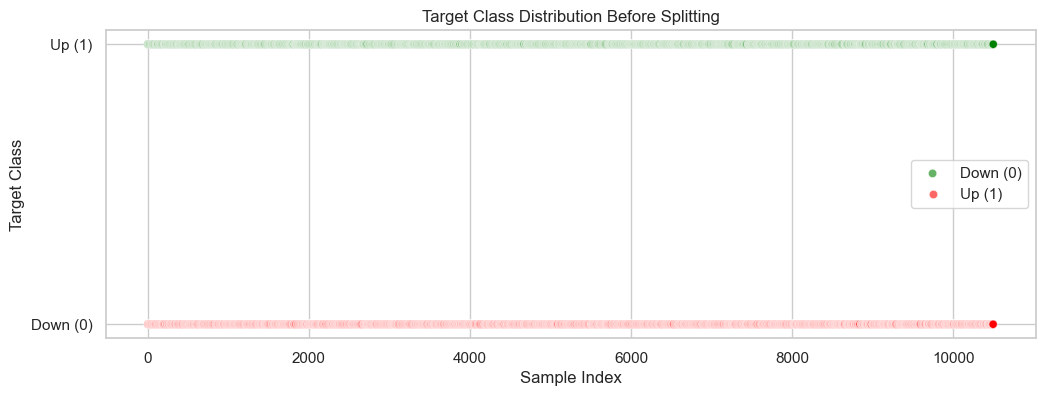

In [55]:
plt.figure(figsize=(12,4))

sns.scatterplot( data=train_markfea, x=train_markfea.index, y="target", hue="target", palette={0:"red", 1:"green"},alpha=0.6)

plt.title("Target Class Distribution Before Splitting")
plt.xlabel("Sample Index")
plt.ylabel("Target Class")

plt.yticks([0,1], ["Down (0)", "Up (1)"])

plt.legend(
    labels=["Down (0)", "Up (1)"]
)

plt.show()

In [37]:

# Separate features and target
X = train_markfea.drop(columns="target")
y = train_markfea["target"]

# Separate numerical and categorical columns
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

# Split into training and validation sets
X_train, X_val, y_train, y_val = train_test_split( X, y, test_size=0.20, random_state=42, stratify=y)

# Numerical pipeline
num_pipeline = Pipeline([("scaler", StandardScaler())])

# Categorical pipeline
cat_pipeline = Pipeline([("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

# Combine both pipelines
preprocessor = ColumnTransformer([("num", num_pipeline, num_cols),("cat", cat_pipeline, cat_cols)])

# Fit on training data and transform
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation data
X_val_processed = preprocessor.transform(X_val)

# Get feature names
feature_names = preprocessor.get_feature_names_out()

# Convert back to DataFrames
X_train_final = pd.DataFrame( X_train_processed, columns=feature_names, index=X_train.index)

X_val_final = pd.DataFrame(X_val_processed,columns=feature_names,index=X_val.index)

# Check shapes
print("X_train_final:", X_train_final.shape)
print("X_val_final:", X_val_final.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape) 

C:\Users\aggos\AppData\Local\Temp\ipykernel_4496\3127113251.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()


X_train_final: (8400, 62)
X_val_final: (2100, 62)
y_train: (8400,)
y_val: (2100,)


In [39]:

RANDOM_STATE = 42
from sklearn.ensemble import ExtraTreesClassifier, VotingClassifier
# Extra Trees
et_model = ExtraTreesClassifier(
    n_estimators=300,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=RANDOM_STATE
)

# LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    random_state=RANDOM_STATE
)

# CatBoost
cat_model = CatBoostClassifier(
    iterations=300,
    learning_rate=0.05,
    depth=6,
    verbose=0,
    random_state=RANDOM_STATE
)

# Soft Voting Ensemble
ensemble_model = VotingClassifier(
    estimators=[
        ("Extra Trees", et_model),
        ("XGBoost", xgb_model),
        ("LightGBM", lgbm_model),
        ("CatBoost", cat_model)
    ],
    voting="soft",
    n_jobs=-1
)

# Dictionary of models
models = {
    "Extra Trees": et_model,
    "XGBoost": xgb_model,
    "LightGBM": lgbm_model,
    "CatBoost": cat_model,
    "Voting Ensemble": ensemble_model
}

# Store results
results = []

for name, model in models.items():

    # Train model
    model.fit(X_train_final, y_train)

    # Predictions
    y_pred = model.predict(X_val_final)
    y_prob = model.predict_proba(X_val_final)[:, 1]

    # Save evaluation metrics
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })

# Comparison table
results_df = pd.DataFrame(results)

# Sort by ROC-AUC (or any metric you prefer)
results_df = results_df.sort_values(by="ROC-AUC", ascending=False)

print(results_df)

[LightGBM] [Info] Number of positive: 4214, number of negative: 4186
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002893 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7440
[LightGBM] [Info] Number of data points in the train set: 8400, number of used features: 61
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.501667 -> initscore=0.006667
[LightGBM] [Info] Start training from score 0.006667
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, be

In [41]:

from scipy.stats import randint, uniform
RANDOM_STATE = 42
# Cross validation setup
cv = StratifiedKFold( n_splits=5, shuffle=True, random_state=RANDOM_STATE)


# Extra Trees
et_model = ExtraTreesClassifier(  random_state=RANDOM_STATE, n_jobs=-1)

et_params = {
    "n_estimators": randint(300, 800),
    "max_depth": randint(10, 30),
    "min_samples_split": randint(2, 8),
    "min_samples_leaf": randint(1, 4),
    "max_features": ["sqrt", "log2", None],
    "bootstrap": [True, False],
    "class_weight": ["balanced", None] 
}


# XGBoost
xgb_model = XGBClassifier(
    random_state=RANDOM_STATE,
    eval_metric="logloss"
)

xgb_params = {
    "n_estimators": randint(300, 800),
    "max_depth": randint(3, 10),
    "learning_rate": uniform(0.01, 0.15),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_weight": randint(1, 8),
    "gamma": uniform(0, 0.5),
    "reg_lambda": uniform(0.5, 3)
}


# LightGBM
lgbm_model = LGBMClassifier(
    random_state=RANDOM_STATE,
    verbose=-1
)

lgbm_params = {
    "n_estimators": randint(300, 800),
    "max_depth": randint(3, 12),
    "learning_rate": uniform(0.01, 0.15),
    "num_leaves": randint(20, 100),
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_samples": randint(10, 50),
    "reg_lambda": uniform(0.5, 3)
}


# CatBoost
cat_model = CatBoostClassifier(
    verbose=0,
    random_state=RANDOM_STATE
)

cat_params = {
    "iterations": randint(300, 800),
    "depth": randint(4, 10),
    "learning_rate": uniform(0.01, 0.15),
    "l2_leaf_reg": uniform(1, 5),
    "subsample": uniform(0.6, 0.4),
    "random_strength": uniform(0, 1)
}



# Function for Random Search
def tune_model(model, params):

    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=params,
        n_iter=30,
        scoring="roc_auc",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1
    )

    search.fit(X_train_final, y_train)

    print("Best Parameters:")
    print(search.best_params_)
    print("Best ROC-AUC:", search.best_score_)

    return search.best_estimator_



# Tune all models

best_et = tune_model(et_model, et_params)

best_xgb = tune_model(xgb_model, xgb_params)

best_lgbm = tune_model(lgbm_model, lgbm_params)

best_cat = tune_model(cat_model, cat_params)



# Voting Ensemble using tuned models

ensemble_model = VotingClassifier(
    estimators=[
        ("Extra Trees", best_et),
        ("XGBoost", best_xgb),
        ("LightGBM", best_lgbm),
        ("CatBoost", best_cat)
    ],
    voting="soft",
    n_jobs=-1
)


# Final models

models = {
    "Extra Trees": best_et,
    "XGBoost": best_xgb,
    "LightGBM": best_lgbm,
    "CatBoost": best_cat,
    "Voting Ensemble": ensemble_model
}



# Evaluation

results = []

for name, model in models.items():

    model.fit(X_train_final, y_train)

    y_pred = model.predict(X_val_final)
    y_prob = model.predict_proba(X_val_final)[:,1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Precision": precision_score(y_val, y_pred),
        "Recall": recall_score(y_val, y_pred),
        "F1 Score": f1_score(y_val, y_pred),
        "ROC-AUC": roc_auc_score(y_val, y_prob)
    })


results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
) 

print(results_df)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'bootstrap': False, 'class_weight': 'balanced', 'max_depth': 10, 'max_features': 'log2', 'min_samples_leaf': 2, 'min_samples_split': 6, 'n_estimators': 535}
Best ROC-AUC: 0.6002482968499502
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'colsample_bytree': np.float64(0.718509402281633), 'gamma': np.float64(0.08263346953150125), 'learning_rate': np.float64(0.01234546101117909), 'max_depth': 3, 'min_child_weight': 1, 'n_estimators': 791, 'reg_lambda': np.float64(1.3804645241541142), 'subsample': np.float64(0.6056319290860338)}
Best ROC-AUC: 0.5923464198067452
Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'colsample_bytree': np.float64(0.7710164073434198), 'learning_rate': np.float64(0.013812869011614277), 'max_depth': 5, 'min_child_samples': 41, 'n_estimators': 530, 'num_leaves': 71, 'reg_lambda': np.float64(2.189826715929151), 'subsample': np

c:\Users\aggos\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_validation.py:489: FitFailedWarning: 
2 fits failed out of a total of 150.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
2 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\aggos\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\model_selection\_validation.py", line 851, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\aggos\AppData\Local\Programs\Python\Python314\Lib\site-packages\catboost\core.py", line 5547, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, s

Best Parameters:
{'depth': 9, 'iterations': 405, 'l2_leaf_reg': np.float64(3.8385016390999573), 'learning_rate': np.float64(0.014696993868333789), 'random_strength': np.float64(0.8422847745949985), 'subsample': np.float64(0.7799016533479063)}
Best ROC-AUC: 0.5893292369458825
             Model  Accuracy  Precision    Recall  F1 Score   ROC-AUC
0      Extra Trees  0.590476   0.591296  0.593542  0.592417  0.622030
4  Voting Ensemble  0.577619   0.576994  0.590693  0.583763  0.615454
1          XGBoost  0.578571   0.578358  0.588794  0.583529  0.615266
2         LightGBM  0.578571   0.579395  0.582146  0.580767  0.610621
3         CatBoost  0.563810   0.562902  0.582146  0.572362  0.604354


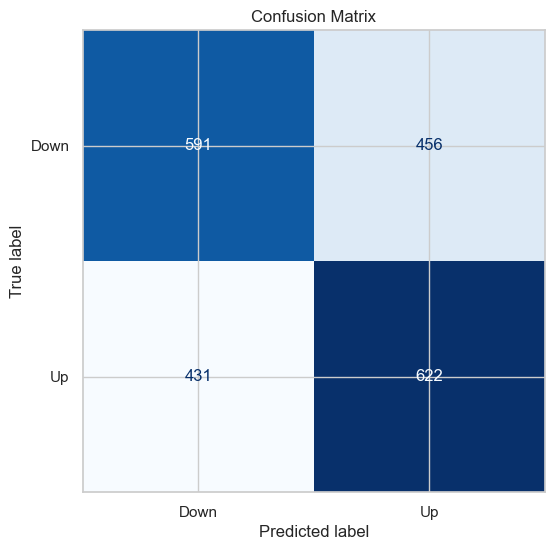

In [42]:
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Predict on validation set
y_pred = ensemble_model.predict(X_val_final)

# Create confusion matrix
cm = confusion_matrix(y_val, y_pred)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Down", "Up"]
)

fig, ax = plt.subplots(figsize=(6,6))
disp.plot(ax=ax, cmap="Blues", colorbar=False)

plt.title("Confusion Matrix")
plt.show()

In [51]:
X_val_final.columns

Index(['num__previous_close', 'num__ma_5', 'num__ma_20', 'num__rsi',
       'num__volume', 'num__news_sentiment', 'num__interest_rate',
       'num__inflation_rate', 'num__oil_price', 'num__usd_local_rate',
       'num__Trend_Strength', 'num__Momentum', 'num__Trend_Direction',
       'num__Relative_RSI', 'num__Real_Interest_Rate', 'num__Oil_FX_Ratio',
       'num__Economic_Stress', 'num__Import_Cost', 'num__Sentiment_Impact',
       'num__Buying_Pressure', 'num__Speculation_Index', 'num__Price_Premium',
       'num__Mean_Reversion', 'num__Relative_Volume', 'num__Liquidity_Score',
       'num__MA_Spread', 'num__Relative_Spread', 'num__RSI_Strength',
       'num__Oil_Revenue_Index', 'num__Naira_Strength', 'num__Oil_Inflation',
       'cat__ticker_ACCESSCORP', 'cat__ticker_AIRTELAFRI',
       'cat__ticker_BUACEMENT', 'cat__ticker_BUAFOODS', 'cat__ticker_CADBURY',
       'cat__ticker_DANGCEM', 'cat__ticker_DANGSUGAR', 'cat__ticker_FBNH',
       'cat__ticker_FCMB', 'cat__ticker_FIDELITYBK',

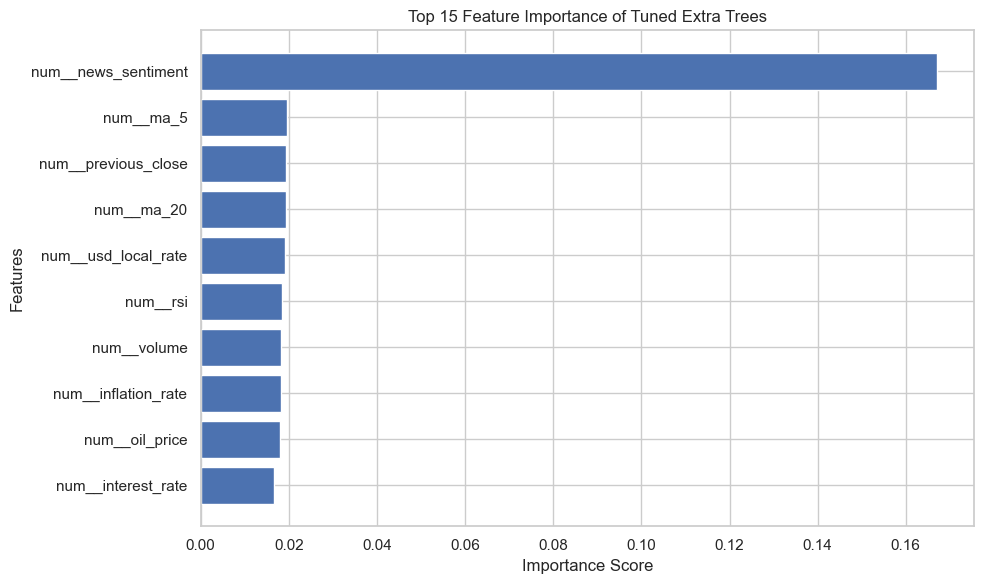

In [44]:
# extract the tuned extra trees 

best_ets = best_et 

# create a dataframe containing the feature names and their importance scores
feature_importance = pd.DataFrame({ "Feature": X_train_final.columns, "Importance": best_ets.feature_importances_ })

# select the top 10 features
top_features = feature_importance.head(10).sort_values( by="Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(top_features["Feature"], top_features["Importance"])

plt.gca().invert_yaxis()

plt.title("Top 15 Feature Importance of Tuned Extra Trees")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

In [57]:

# Separate columns
num_cols = X_train.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns

# Pipelines
num_pipeline = Pipeline([ ("scaler", StandardScaler())])

cat_pipeline = Pipeline([("onehot", OneHotEncoder(handle_unknown="ignore"))])

# Combine preprocessing
preprocessor = ColumnTransformer([("num", num_pipeline, num_cols), ("cat", cat_pipeline, cat_cols)])

# FIT + TRANSFORM TRAIN DATA
X_train_final = preprocessor.fit_transform(X_train)

# TRANSFORM VALIDATION AND TEST DATA
X_val_final = preprocessor.transform(X_val)
test_markfea_final = preprocessor.transform(test_markfea)

# Get feature names after encoding
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrames
X_train_final = pd.DataFrame(X_train_final.toarray() if hasattr(X_train_final, "toarray") else X_train_final,columns=feature_names)

X_val_final = pd.DataFrame(
    X_val_final.toarray() if hasattr(X_val_final, "toarray") else X_val_final,
columns=feature_names
)

X_test = pd.DataFrame( test_markfea_final.toarray() if hasattr(test_markfea_final, "toarray") else test_markfea_final,columns=feature_names) 

C:\Users\aggos\AppData\Local\Temp\ipykernel_4496\495647463.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(include=["object", "category"]).columns


In [ ]:
#run X_train_final on extra trees and pred on actual test data set. 
 
#extra_tree_model = ExtraTreesClassifier(n_estimators= ,          # number of trees
    #max_depth= ,             # maximum depth of each tree
    #min_samples_split= ,     # minimum samples needed to split a node
    #min_samples_leaf= ,      # minimum samples required at a leaf node
    #max_features= ,          # number of features considered at each split
    # class_weight= ,          # handles class imbalance
  #  random_state=42,
 #   n_jobs=-1
#)